In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import itertools
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator
import math
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, LinearRegression

In [4]:
# 1.1

# seed
random_state = np.random.RandomState(77)

# Матрица ковариаций
cov = np.array([
    [1.0, 0.9, 0.0, 0.0],
    [0.9, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 0.0],
    [0.0, 0.0, 0.0, 1.0],
])

X = random_state.multivariate_normal(mean=np.zeros(4), cov=cov, size=1000)

# Добавим несколько объектов с пропуском и с нулевым значением.
n_special = 67
n_nan = n_special + random_state.randint(-3, 5)
n_zero = n_special + random_state.randint(-6, 8)
nan_rows = random_state.choice(X.shape[0], size=n_nan, replace=False)
available_rows = np.setdiff1d(np.arange(X.shape[0]), nan_rows)
zero_rows = random_state.choice(available_rows, size=n_zero, replace=False)
nan_features = random_state.choice([2, 3], size=n_nan)  # C или D
zero_features = random_state.choice([2, 3], size=n_zero)  # C или D
X[nan_rows, nan_features] = np.nan
X[zero_rows, zero_features] = 0.0


dfS00 = pd.DataFrame(X, columns=["A", "B", "C", "D"])
dfS00["class"] = "S00" 
dfS00.head()

,A,B,C,D,class
0,-0.309951,-0.127572,-0.579758,0.661531,S00
1,-0.102307,-0.807029,0.275548,-1.974709,S00
2,-1.788950,-1.268419,0.305890,-0.724795,S00
3,0.642975,1.402088,-0.639051,-0.976578,S00
4,1.289438,1.217662,-0.073913,-0.189162,S00


In [5]:
# 1.2

class_col = "class"
feature_cols = dfS00.select_dtypes(include="number").columns.tolist()

dimensions = pd.DataFrame({
    "Показатель": ["Объекты", "Столбцы (включая класс)", "Количественные признаки", "Классы"],
    "Значение": [len(dfS00), dfS00.shape[1], len(feature_cols), dfS00[class_col].nunique()]
})

column_types = dfS00.dtypes.astype(str).rename("Тип").to_frame()
column_types.index.name = "Признак"

class_counts = dfS00.groupby(class_col, dropna=False).size().rename("Объекты").to_frame()
has_nan = dfS00[feature_cols].isna().any(axis=1)
has_zero = dfS00[feature_cols].eq(0).any(axis=1)
class_counts["Строки с NaN"] = has_nan.groupby(dfS00[class_col], dropna=False).sum()
class_counts["Строки с нулями"] = has_zero.groupby(dfS00[class_col], dropna=False).sum()

sample_estimates = dfS00[feature_cols].describe().T
sample_estimates["variance"] = dfS00[feature_cols].var()
sample_estimates["skewness"] = dfS00[feature_cols].skew()
sample_estimates = sample_estimates.rename(columns={
    "count": "Число значений", "mean": "Среднее", "std": "Станд. отклонение",
    "min": "Минимум", "25%": "25-й процентиль", "50%": "Медиана",
    "75%": "75-й процентиль", "max": "Максимум",
    "variance": "Дисперсия", "skewness": "Асимметрия"
})

print("Размерность датасета")
display(dimensions)
print("Типы признаков")
display(column_types)
print("Число объектов, строк с NaN и нулями по классам")
display(class_counts)
print("Оценки выборки для количественных признаков")
display(sample_estimates)

Размерность датасета


,Показатель,Значение
0,Объекты,1000
1,Столбцы (включая класс),5
2,Количественные признаки,4
3,Классы,1


Типы признаков


,Тип
Признак,
A,float64
B,float64
C,float64
D,float64
class,str


Число объектов, строк с NaN и нулями по классам


,Объекты,Строки с NaN,Строки с нулями
class,,,
S00,1000,71,73


Оценки выборки для количественных признаков


,Число значений,Среднее,Станд. отклонение,Минимум,25-й процентиль,Медиана,75-й процентиль,Максимум,Дисперсия,Асимметрия
A,1000.0,-0.013353,1.007651,-3.532631,-0.704129,-0.025737,0.659925,3.258080,1.015360,-0.079523
B,1000.0,-0.017508,1.016468,-4.071016,-0.670339,0.010011,0.653140,3.419242,1.033208,-0.150769
C,965.0,-0.044356,1.009395,-3.450430,-0.706454,0.000000,0.631735,2.618430,1.018878,-0.108959
D,964.0,0.030949,0.982013,-3.431684,-0.628902,0.000000,0.655840,2.912494,0.964350,0.048348


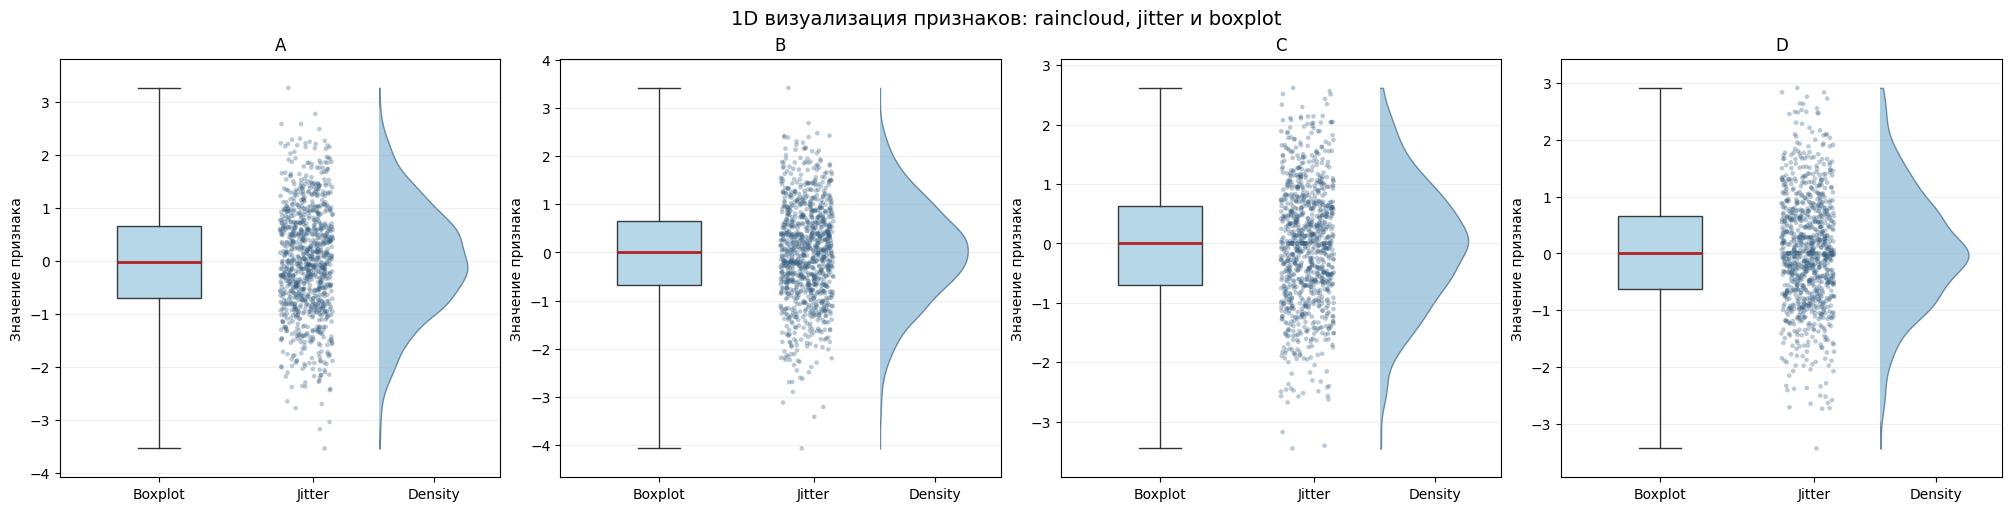

In [6]:
# 1.3 

BOX_STAT_ESTIMATORS = {
    "center": np.median,
    "q1": lambda values: np.percentile(values, 25),
    "q3": lambda values: np.percentile(values, 75),
    "lower_whisker": np.min,
    "upper_whisker": np.max,
}

feature_cols = dfS00.select_dtypes(include="number").columns.tolist()
jitter_rng = np.random.RandomState(77)

fig, axes = plt.subplots(
    1, len(feature_cols),
    figsize=(5 * len(feature_cols), 5),
    squeeze=False,
    constrained_layout=True
)
axes = axes.ravel()

for ax, feature in zip(axes, feature_cols):
    values = dfS00[feature].dropna().to_numpy(dtype=float)
    estimates = {
        "q1": float(BOX_STAT_ESTIMATORS["q1"](values)),
        "med": float(BOX_STAT_ESTIMATORS["center"](values)),
        "q3": float(BOX_STAT_ESTIMATORS["q3"](values)),
        "whislo": float(BOX_STAT_ESTIMATORS["lower_whisker"](values)),
        "whishi": float(BOX_STAT_ESTIMATORS["upper_whisker"](values)),
        "fliers": [],
    }

    # Boxplot: позиция 0;
    ax.bxp(
        [estimates],
        positions=[0],
        widths=0.38,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#9ecae1", "alpha": 0.75},
        medianprops={"color": "#b22222", "linewidth": 2},
        whiskerprops={"color": "#333333"},
        capprops={"color": "#333333"},
    )

    jitter = jitter_rng.uniform(0.04, 0.28, size=len(values))
    ax.scatter(0.83 - jitter, values, s=11, alpha=0.32, color="#315a7d", edgecolors="none", rasterized=True)

    violin = ax.violinplot([values], positions=[1.0], widths=0.8, showextrema=False)
    spread = float(np.ptp(values))
    if spread == 0:
        spread = 1.0
    y_min = float(np.min(values) - 0.08 * spread)
    y_max = float(np.max(values) + 0.08 * spread)
    clip_half = Rectangle(
        (1.0, y_min), 1.0, y_max - y_min,
        transform=ax.transData
    )
    violin["bodies"][0].set_facecolor("#80b1d3")
    violin["bodies"][0].set_edgecolor("#315a7d")
    violin["bodies"][0].set_alpha(0.65)
    violin["bodies"][0].set_clip_path(clip_half)

    ax.set_xlim(-0.45, 1.55)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks([0, 0.70, 1.25], ["Boxplot", "Jitter", "Density"])
    ax.set_title(feature)
    ax.set_ylabel("Значение признака")
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "1D визуализация признаков: raincloud, jitter и boxplot",
    fontsize=14
)
plt.show()

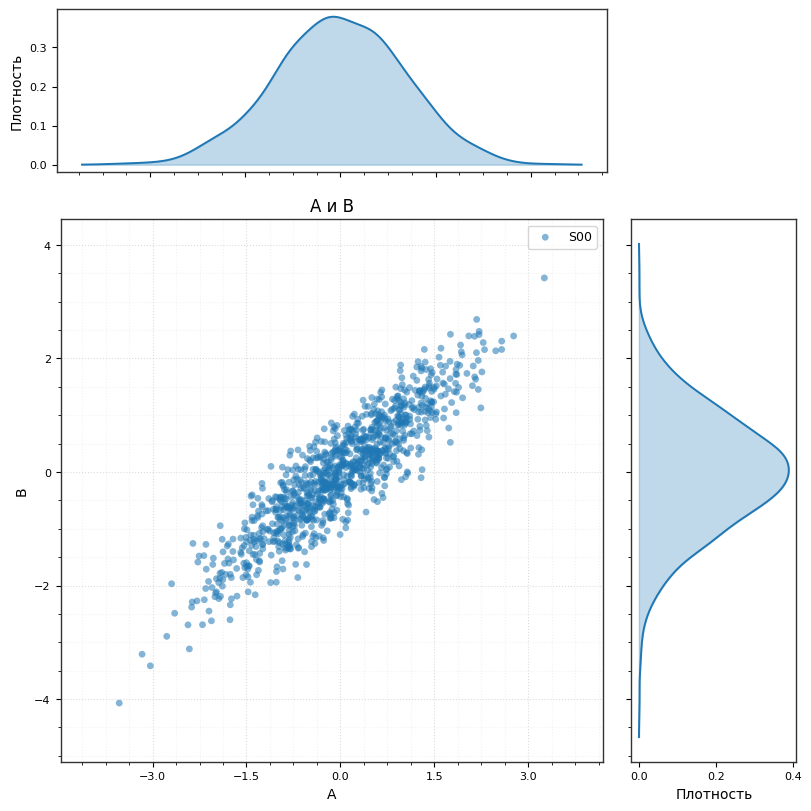

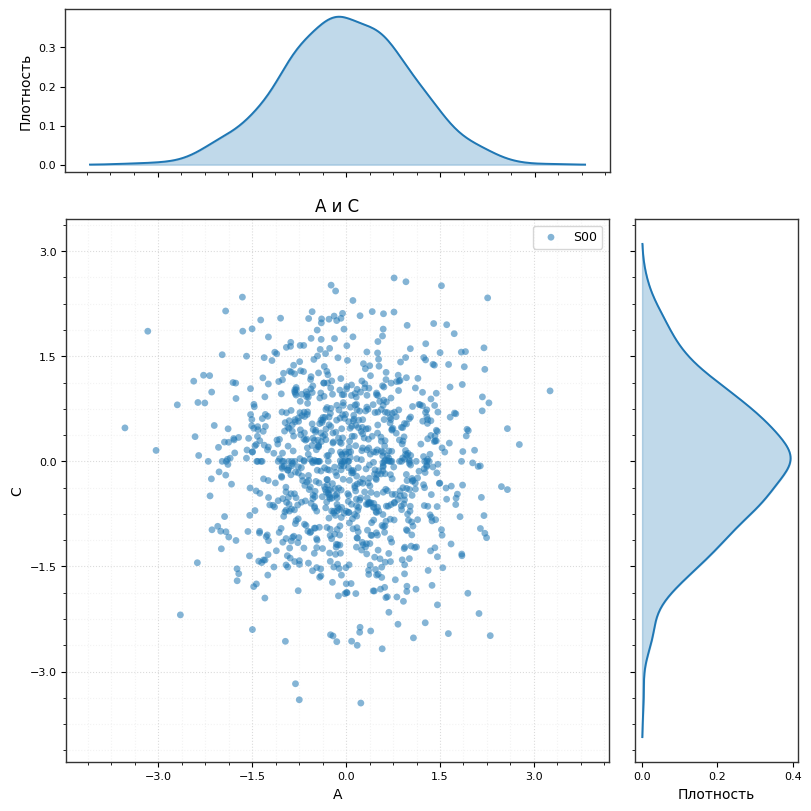

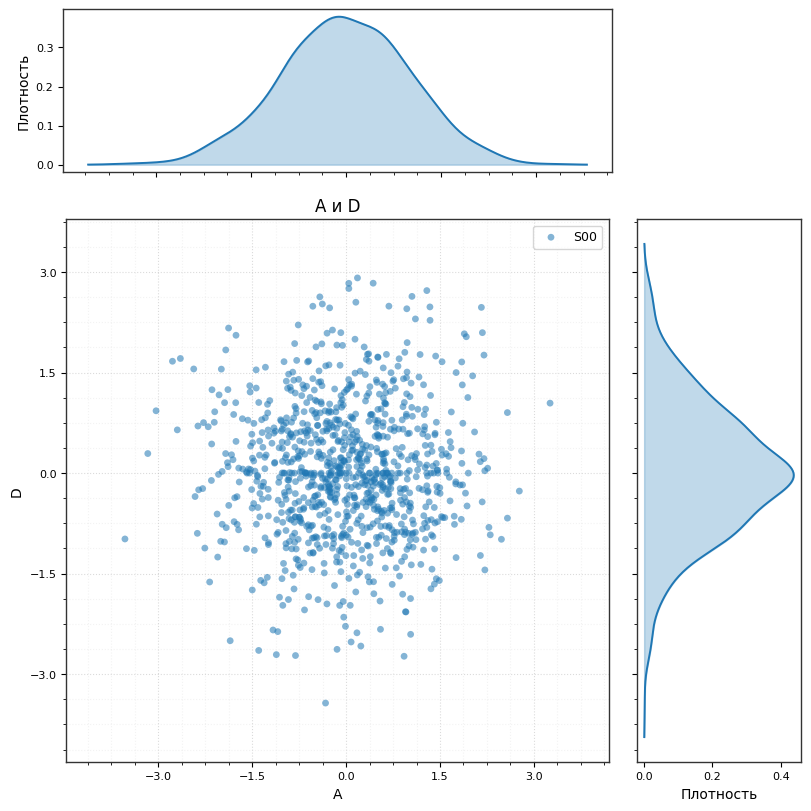

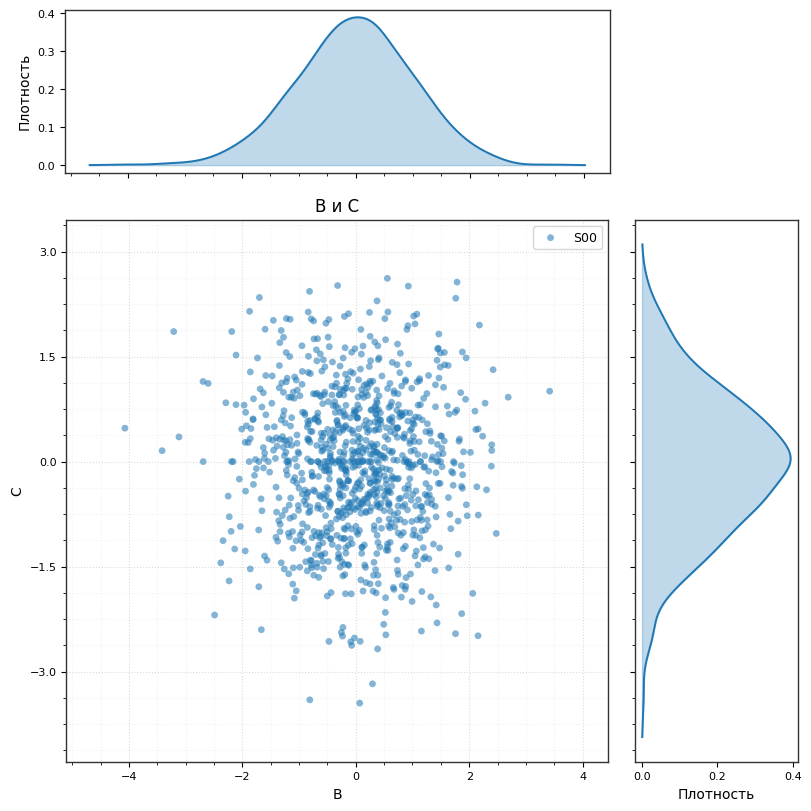

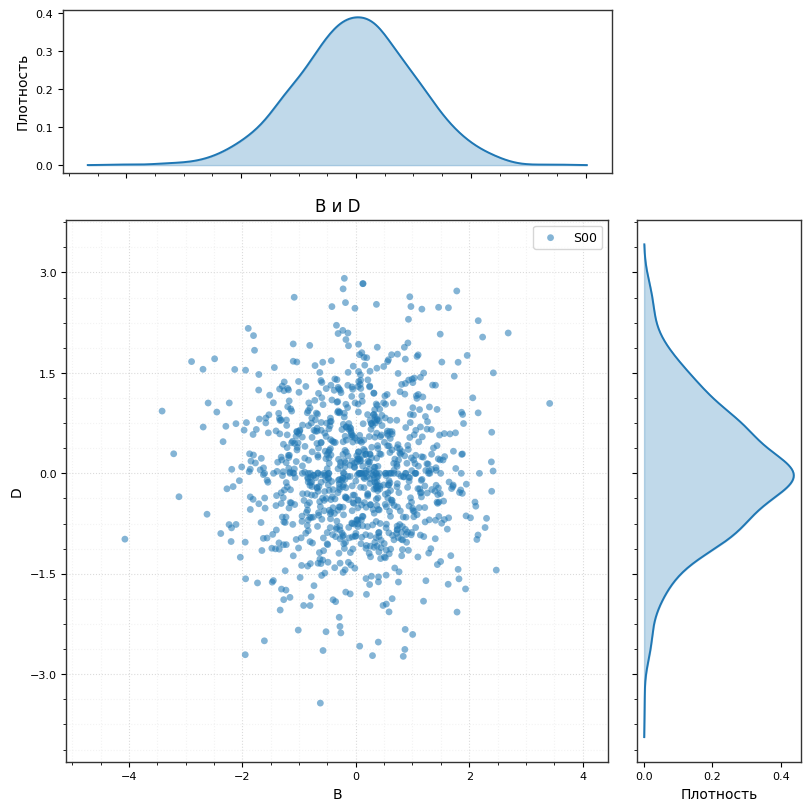

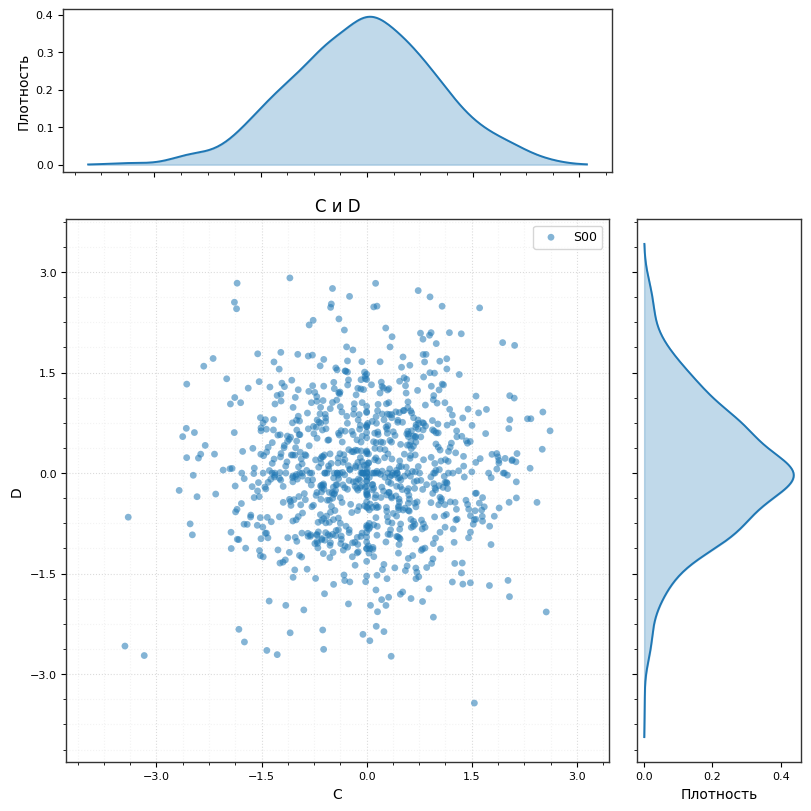

In [7]:
# 1.4

PAIRPLOT_CONFIG = {
    "features": None,
    "class_column": "class",
    "figure_size": (8, 8),
    "square": True,
    "show_titles": True,
    "show_legend": True,
    "scatter_size": 24,
    "scatter_alpha": 0.55,
    "density_alpha": 0.28,
    "class_density_alpha": None,
    "axis_color": "#333333",
    "axis_linewidth": 1.0,
    "ticks": {
        "x": {"major_step": None, "major_count": 6, "minor_step": None, "minor_count": 4},
        "y": {"major_step": None, "major_count": 6, "minor_step": None, "minor_count": 4},
    },
    "grid": {
        "show": True,
        "major_color": "#b0b0b0",
        "major_alpha": 0.45,
        "minor_color": "#d0d0d0",
        "minor_alpha": 0.25,
        "linestyle": ":",
    },
    "fonts": {
        "title": {"family": "DejaVu Sans", "size": 12},
        "axis_label": {"family": "DejaVu Sans", "size": 10},
        "tick": {"family": "DejaVu Sans", "size": 8},
        "legend": {"family": "DejaVu Sans", "size": 9},
    },
    "class_colors": None,
    "class_markers": None,
    "kde_grid_size": 240,
}


def gaussian_kde_1d(values, grid):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return None

    std = float(np.std(values, ddof=1))
    if std == 0:
        return None

    bandwidth = 1.06 * std * len(values) ** (-1 / 5)
    bandwidth = max(bandwidth, np.finfo(float).eps)
    z = (grid[:, None] - values[None, :]) / bandwidth
    return np.exp(-0.5 * z ** 2).mean(axis=1) / (bandwidth * np.sqrt(2 * np.pi))


def set_feature_tick_locator(axis, axis_name, tick_config):
    ticker_axis = axis.xaxis if axis_name == "x" else axis.yaxis
    major_step = tick_config["major_step"]
    if major_step is not None:
        ticker_axis.set_major_locator(MultipleLocator(major_step))
    else:
        ticker_axis.set_major_locator(MaxNLocator(nbins=tick_config["major_count"]))

    minor_step = tick_config["minor_step"]
    if minor_step is not None:
        ticker_axis.set_minor_locator(MultipleLocator(minor_step))
    else:
        ticker_axis.set_minor_locator(
            AutoMinorLocator(n=tick_config["minor_count"])
        )


feature_cols = PAIRPLOT_CONFIG["features"]
if feature_cols is None:
    feature_cols = dfS00.select_dtypes(include="number").columns.tolist()

class_col = PAIRPLOT_CONFIG["class_column"]
feature_cols = [feature for feature in feature_cols if feature != class_col]
classes = dfS00[class_col].dropna().unique().tolist()
default_colors = plt.get_cmap("tab10")
default_markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
custom_colors = PAIRPLOT_CONFIG["class_colors"] or {}
custom_markers = PAIRPLOT_CONFIG["class_markers"] or {}
custom_density_alpha = PAIRPLOT_CONFIG["class_density_alpha"] or {}
class_colors = {
    value: custom_colors.get(value, default_colors(i % 10))
    for i, value in enumerate(classes)
}
class_markers = {
    value: custom_markers.get(value, default_markers[i % len(default_markers)])
    for i, value in enumerate(classes)
}

for x_feature, y_feature in itertools.combinations(feature_cols, 2):
    fig_size = PAIRPLOT_CONFIG["figure_size"]
    if PAIRPLOT_CONFIG["square"]:
        side = max(fig_size)
        fig_size = (side, side)

    fig = plt.figure(figsize=fig_size, constrained_layout=True)
    grid_spec = fig.add_gridspec(
        2, 2,
        width_ratios=(4.5, 1.35),
        height_ratios=(1.35, 4.5),
        wspace=0.05,
        hspace=0.05,
    )
    ax_top = fig.add_subplot(grid_spec[0, 0])
    ax = fig.add_subplot(grid_spec[1, 0], sharex=ax_top)
    ax_right = fig.add_subplot(grid_spec[1, 1], sharey=ax)
    fig.add_subplot(grid_spec[0, 1]).axis("off")

    for class_value in classes:
        class_data = dfS00.loc[
            dfS00[class_col] == class_value, [x_feature, y_feature]
        ].dropna()
        ax.scatter(
            class_data[x_feature],
            class_data[y_feature],
            s=PAIRPLOT_CONFIG["scatter_size"],
            alpha=PAIRPLOT_CONFIG["scatter_alpha"],
            color=class_colors[class_value],
            marker=class_markers[class_value],
            label=str(class_value),
            edgecolors="none",
        )

    for class_value in classes:
        class_x = dfS00.loc[
            dfS00[class_col] == class_value, x_feature
        ].dropna().to_numpy(dtype=float)
        class_y = dfS00.loc[
            dfS00[class_col] == class_value, y_feature
        ].dropna().to_numpy(dtype=float)

        for values, feature, density_axis, direction in (
            (class_x, x_feature, ax_top, "x"),
            (class_y, y_feature, ax_right, "y"),
        ):
            if len(values) == 0:
                continue
            spread = float(np.ptp(values))
            if spread == 0:
                spread = max(abs(float(values[0])) * 0.1, 1.0)
            kde_grid = np.linspace(
                float(np.min(values) - 0.08 * spread),
                float(np.max(values) + 0.08 * spread),
                PAIRPLOT_CONFIG["kde_grid_size"],
            )
            density = gaussian_kde_1d(values, kde_grid)
            if density is None:
                continue

            color = class_colors[class_value]
            alpha = custom_density_alpha.get(class_value, PAIRPLOT_CONFIG["density_alpha"])
            if direction == "x":
                density_axis.fill_between(
                    kde_grid, 0, density, color=color, alpha=alpha
                )
                density_axis.plot(kde_grid, density, color=color, linewidth=1.4)
            else:
                density_axis.fill_betweenx(
                    kde_grid, 0, density, color=color, alpha=alpha
                )
                density_axis.plot(density, kde_grid, color=color, linewidth=1.4)

    if PAIRPLOT_CONFIG["square"]:
        ax.set_box_aspect(1)

    ax.set_xlabel(x_feature, **PAIRPLOT_CONFIG["fonts"]["axis_label"])
    ax.set_ylabel(y_feature, **PAIRPLOT_CONFIG["fonts"]["axis_label"])
    ax_top.set_ylabel("Плотность", **PAIRPLOT_CONFIG["fonts"]["axis_label"])
    ax_right.set_xlabel("Плотность", **PAIRPLOT_CONFIG["fonts"]["axis_label"])

    if PAIRPLOT_CONFIG["show_titles"]:
        ax.set_title(
            f"{x_feature} и {y_feature}",
            **PAIRPLOT_CONFIG["fonts"]["title"],
        )

    if PAIRPLOT_CONFIG["show_legend"]:
        ax.legend(prop=PAIRPLOT_CONFIG["fonts"]["legend"])

    set_feature_tick_locator(ax, "x", PAIRPLOT_CONFIG["ticks"]["x"])
    set_feature_tick_locator(ax, "y", PAIRPLOT_CONFIG["ticks"]["y"])
    ax_top.tick_params(labelbottom=False)
    ax_right.tick_params(labelleft=False)

    if PAIRPLOT_CONFIG["grid"]["show"]:
        grid_options = PAIRPLOT_CONFIG["grid"]
        ax.set_axisbelow(True)
        ax.grid(
            True, which="major",
            color=grid_options["major_color"],
            alpha=grid_options["major_alpha"],
            linestyle=grid_options["linestyle"],
        )
        ax.grid(
            True, which="minor",
            color=grid_options["minor_color"],
            alpha=grid_options["minor_alpha"],
            linestyle=grid_options["linestyle"],
        )

    # Цвет и толщина рамок всех частей рисунка.
    for axis in (ax, ax_top, ax_right):
        for spine in axis.spines.values():
            spine.set_color(PAIRPLOT_CONFIG["axis_color"])
            spine.set_linewidth(PAIRPLOT_CONFIG["axis_linewidth"])
        for label in axis.get_xticklabels() + axis.get_yticklabels():
            label.set_fontfamily(PAIRPLOT_CONFIG["fonts"]["tick"]["family"])
            label.set_fontsize(PAIRPLOT_CONFIG["fonts"]["tick"]["size"])

    plt.show()
    plt.close(fig)

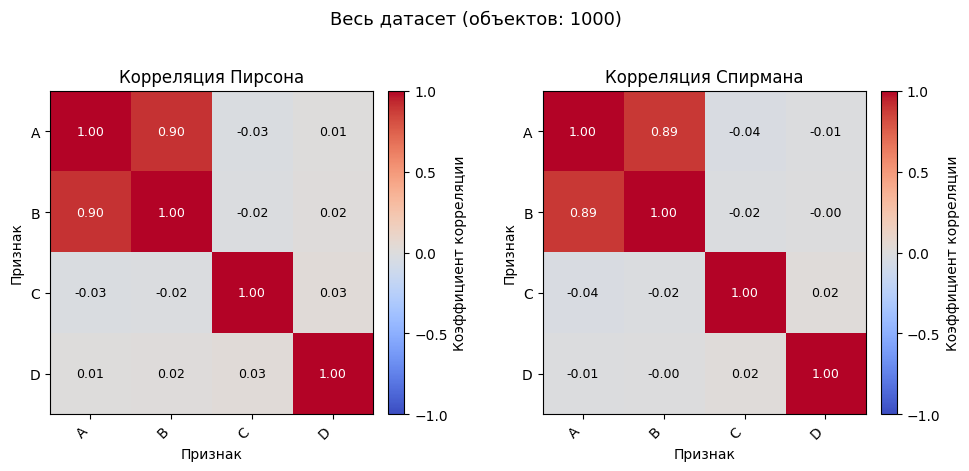

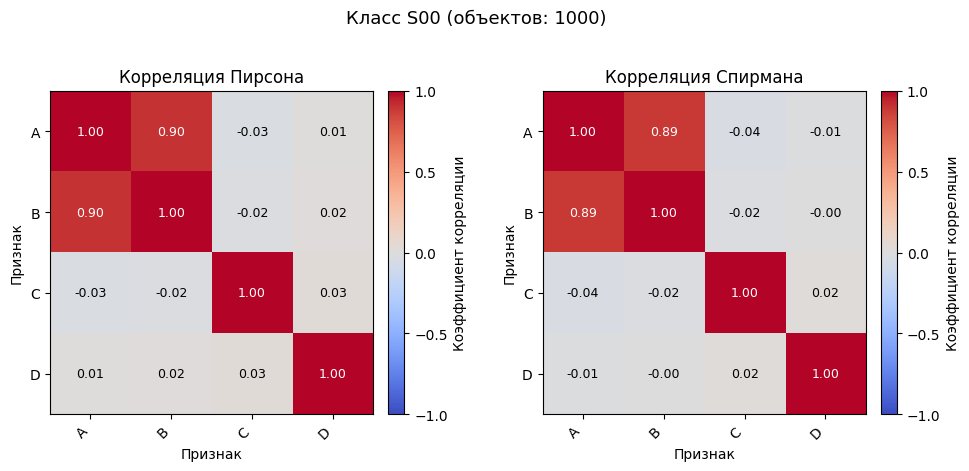

In [ ]:
# 1.5

class_col = "class"
feature_cols = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != class_col
]

HEATMAP_CONFIG = {
    "cmap": "coolwarm",
    "vmin": -1,
    "vmax": 1,
    "annotation_size": 9,
    "figure_height_per_feature": 1.15,
}

def plot_correlation_heatmaps(data, section_title):
    methods = [
        ("Корреляция Пирсона", "pearson"),
        ("Корреляция Спирмана", "spearman"),
    ]
    n_features = len(feature_cols)
    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, max(4, HEATMAP_CONFIG["figure_height_per_feature"] * n_features)),
        squeeze=False,
    )
    cmap = plt.get_cmap(HEATMAP_CONFIG["cmap"]).copy()
    cmap.set_bad("#d9d9d9")

    for ax, (method_title, method_name) in zip(axes.ravel(), methods):
        correlation = data[feature_cols].corr(method=method_name)
        values = correlation.to_numpy(dtype=float)
        image = ax.imshow(np.ma.masked_invalid(values),cmap=cmap, vmin=HEATMAP_CONFIG["vmin"], vmax=HEATMAP_CONFIG["vmax"])

        ax.set_xticks(range(n_features), feature_cols, rotation=45, ha="right")
        ax.set_yticks(range(n_features), feature_cols)
        ax.set_title(method_title)
        ax.set_xlabel("Признак")
        ax.set_ylabel("Признак")
        ax.set_aspect("equal")

        for row in range(n_features):
            for column in range(n_features):
                value = values[row, column]
                label = "—" if np.isnan(value) else f"{value:.2f}"
                text_color = "white" if np.isfinite(value) and abs(value) >= 0.55 else "black"
                ax.text(column, row, label, ha="center", va="center", color=text_color, fontsize=HEATMAP_CONFIG["annotation_size"])

        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, ticks=np.linspace(-1, 1, 5), label="Коэффициент корреляции")

    fig.suptitle(f"{section_title} (объектов: {len(data)})", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()
    plt.close(fig)


# Оценка по всему датасету.
plot_correlation_heatmaps(dfS00, "Весь датасет")

# Та же оценка отдельно для каждого класса.
for class_value in dfS00[class_col].dropna().unique():
    class_data = dfS00.loc[dfS00[class_col] == class_value]
    plot_correlation_heatmaps(class_data, f"Класс {class_value}")

,Датасет,"Доля новых удалений, %",Новых удалений,Исходно NaN,Итоговое число NaN,"Итоговый NaN от числа ячеек, %",Объектов для scatterplot
0,dfSd00,0,0,71,71,1.77,1000
1,dfSd01,1,40,71,111,2.77,985
2,dfSd02,2,80,71,151,3.77,967
3,dfSd05,5,200,71,271,6.78,905
4,dfSd10,10,400,71,471,11.78,815
5,dfSd20,20,800,71,871,21.77,646
6,dfSd50,50,2000,71,2071,51.77,248
7,dfSd80,80,3200,71,3271,81.78,47


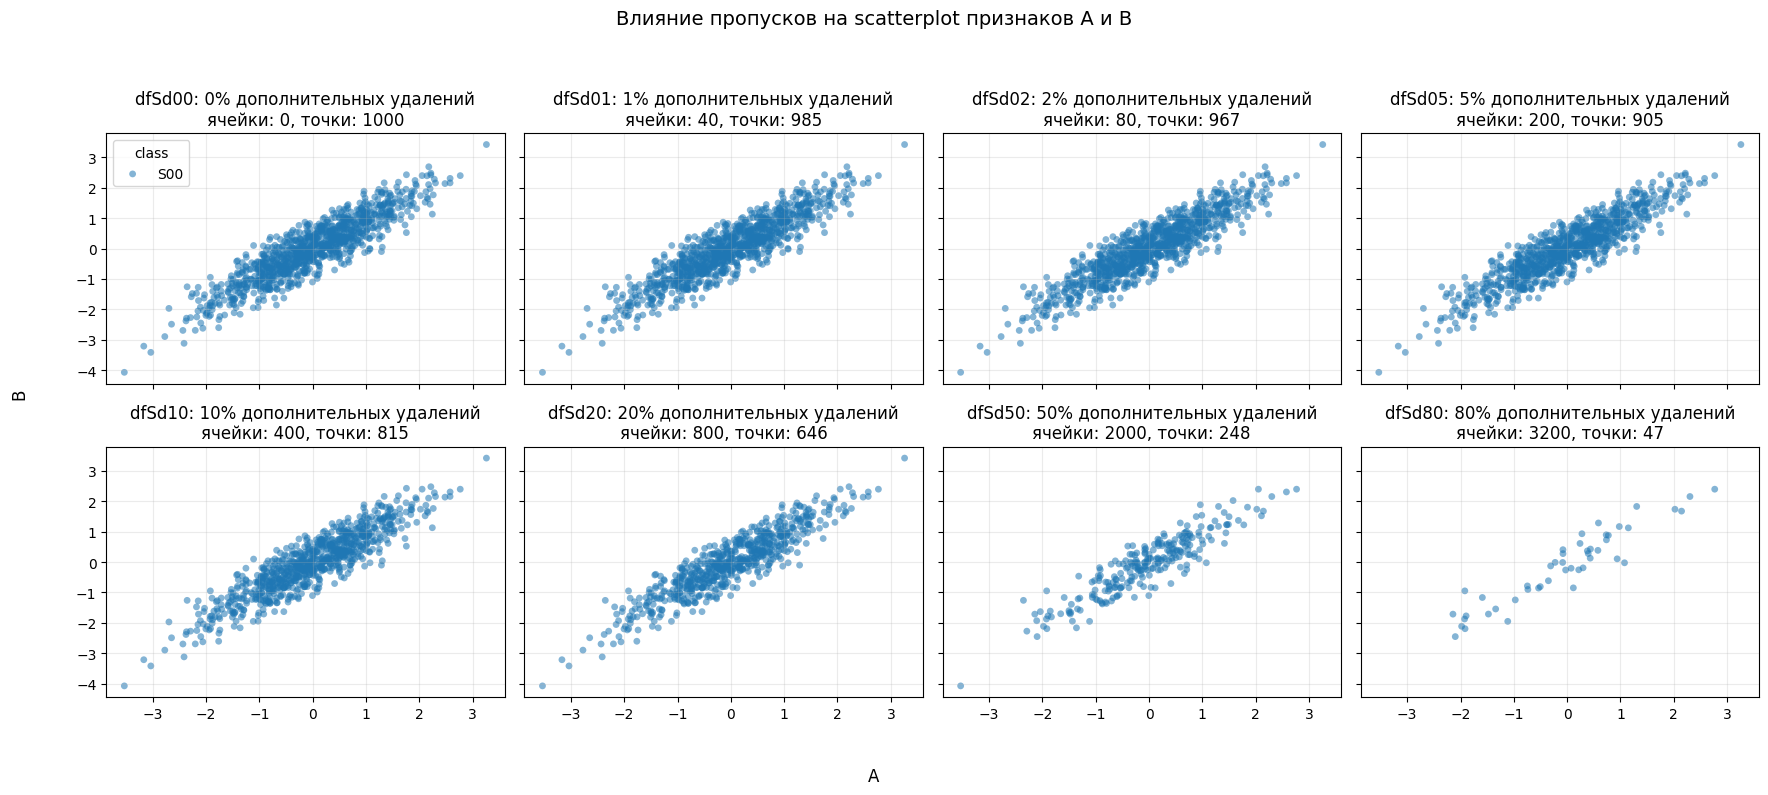

In [11]:
# 1.6

import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MISSING_PERCENTAGES = [0, 1, 2, 5, 10, 20, 50, 80]
MASK_SEED = 1601
CLASS_COLUMN = "class"
SELECTED_PAIR = ("A", "B")
PANEL_COLUMNS = 4
SCATTER_ALPHA = 0.55
SCATTER_SIZE = 24
SHOW_LEGEND = True

feature_columns = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != CLASS_COLUMN
]
x_feature, y_feature = SELECTED_PAIR

source_values = dfS00[feature_columns].to_numpy(dtype=float, copy=True)
n_rows, n_features = source_values.shape
n_feature_cells = n_rows * n_features
observed_flat_indices = np.flatnonzero(~np.isnan(source_values).ravel())
mask_rng = np.random.RandomState(MASK_SEED)
random_cell_order = mask_rng.permutation(observed_flat_indices)

dfSd_datasets = {}
missing_summary_rows = []
original_nan_count = int(np.isnan(source_values).sum())

for percent in MISSING_PERCENTAGES:
    n_to_remove = int(round(n_feature_cells * percent / 100))

    clone = dfS00.copy(deep=True)
    clone_values = source_values.copy()
    selected_flat_cells = random_cell_order[:n_to_remove]
    clone_values.ravel()[selected_flat_cells] = np.nan
    clone[feature_columns] = clone_values

    dataset_name = f"dfSd{percent:02d}"
    dfSd_datasets[dataset_name] = clone
    globals()[dataset_name] = clone

    valid_pair_objects = int(
        clone[[x_feature, y_feature]].notna().all(axis=1).sum()
    )
    total_missing = int(clone[feature_columns].isna().sum().sum())
    missing_summary_rows.append({
        "Датасет": dataset_name,
        "Доля новых удалений, %": percent,
        "Новых удалений": n_to_remove,
        "Исходно NaN": original_nan_count,
        "Итоговое число NaN": total_missing,
        "Итоговый NaN от числа ячеек, %": round(
            100 * total_missing / n_feature_cells, 2
        ),
        "Объектов для scatterplot": valid_pair_objects,
    })

missing_summary = pd.DataFrame(missing_summary_rows)
display(missing_summary)

class_values = dfS00[CLASS_COLUMN].dropna().unique().tolist()
color_map = plt.get_cmap("tab10")
default_markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
custom_colors = {}
custom_markers = {}
class_colors = {
    value: custom_colors.get(value, color_map(i % 10))
    for i, value in enumerate(class_values)
}
class_markers = {
    value: custom_markers.get(value, default_markers[i % len(default_markers)])
    for i, value in enumerate(class_values)
}

n_columns = min(PANEL_COLUMNS, len(MISSING_PERCENTAGES))
n_panel_rows = math.ceil(len(MISSING_PERCENTAGES) / n_columns)
fig, axes = plt.subplots(
    n_panel_rows,
    n_columns,
    figsize=(4.5 * n_columns, 4 * n_panel_rows),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for ax, percent in zip(axes.flat, MISSING_PERCENTAGES):
    dataset_name = f"dfSd{percent:02d}"
    clone = dfSd_datasets[dataset_name]
    valid_pair = clone[[x_feature, y_feature]].notna().all(axis=1)
    n_valid = int(valid_pair.sum())

    for class_value in class_values:
        class_mask = valid_pair & clone[CLASS_COLUMN].eq(class_value)
        class_data = clone.loc[class_mask, [x_feature, y_feature]]
        ax.scatter(
            class_data[x_feature],
            class_data[y_feature],
            color=class_colors[class_value],
            marker=class_markers[class_value],
            alpha=SCATTER_ALPHA,
            s=SCATTER_SIZE,
            edgecolors="none",
            label=str(class_value),
        )

    n_removed = int(
        missing_summary_rows[MISSING_PERCENTAGES.index(percent)]["Новых удалений"]
    )
    ax.set_title(
        f"{dataset_name}: {percent}% дополнительных удалений\n"
        f"ячейки: {n_removed}, точки: {n_valid}"
    )
    ax.grid(True, alpha=0.25)
    if SHOW_LEGEND and ax is axes.flat[0]:
        ax.legend(title=CLASS_COLUMN)

for ax in axes.flat[len(MISSING_PERCENTAGES):]:
    ax.set_visible(False)

fig.supxlabel(x_feature)
fig.supylabel(y_feature)
fig.suptitle(
    f"Влияние пропусков на scatterplot признаков {x_feature} и {y_feature}",
    fontsize=14,
)
fig.tight_layout(rect=(0.03, 0.03, 1, 0.94))
plt.show()
plt.close(fig)

,Датасет,NaN до заполнения,NaN после заполнения
0,dfSd00med,71,0
1,dfSd01med,111,0
2,dfSd02med,151,0
3,dfSd05med,271,0
4,dfSd10med,471,0
5,dfSd20med,871,0
6,dfSd50med,2071,0
7,dfSd80med,3271,0


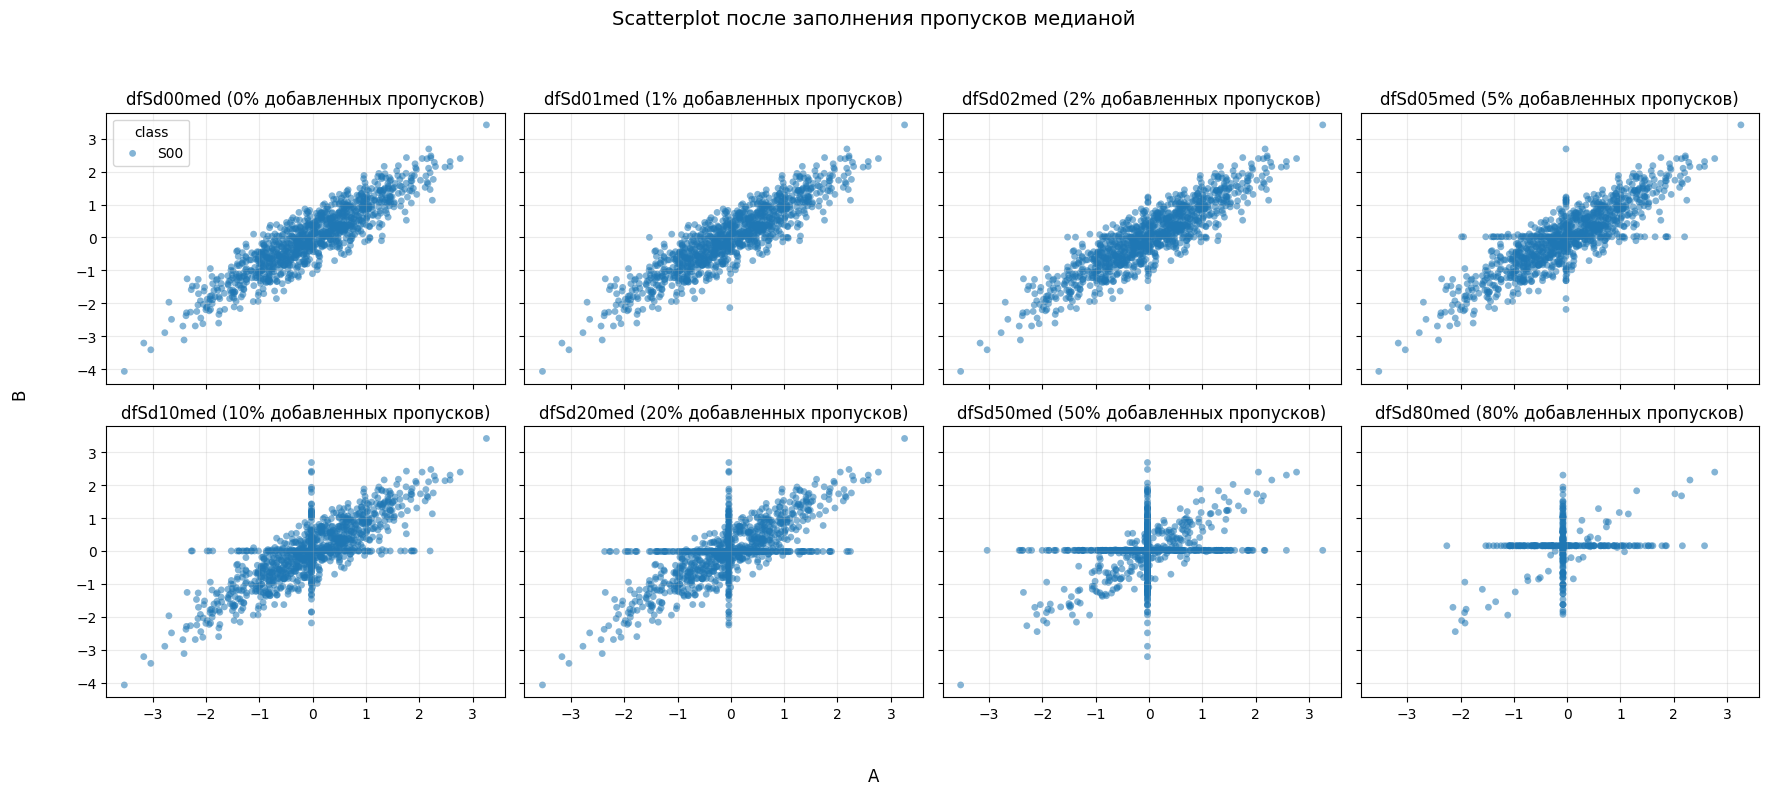

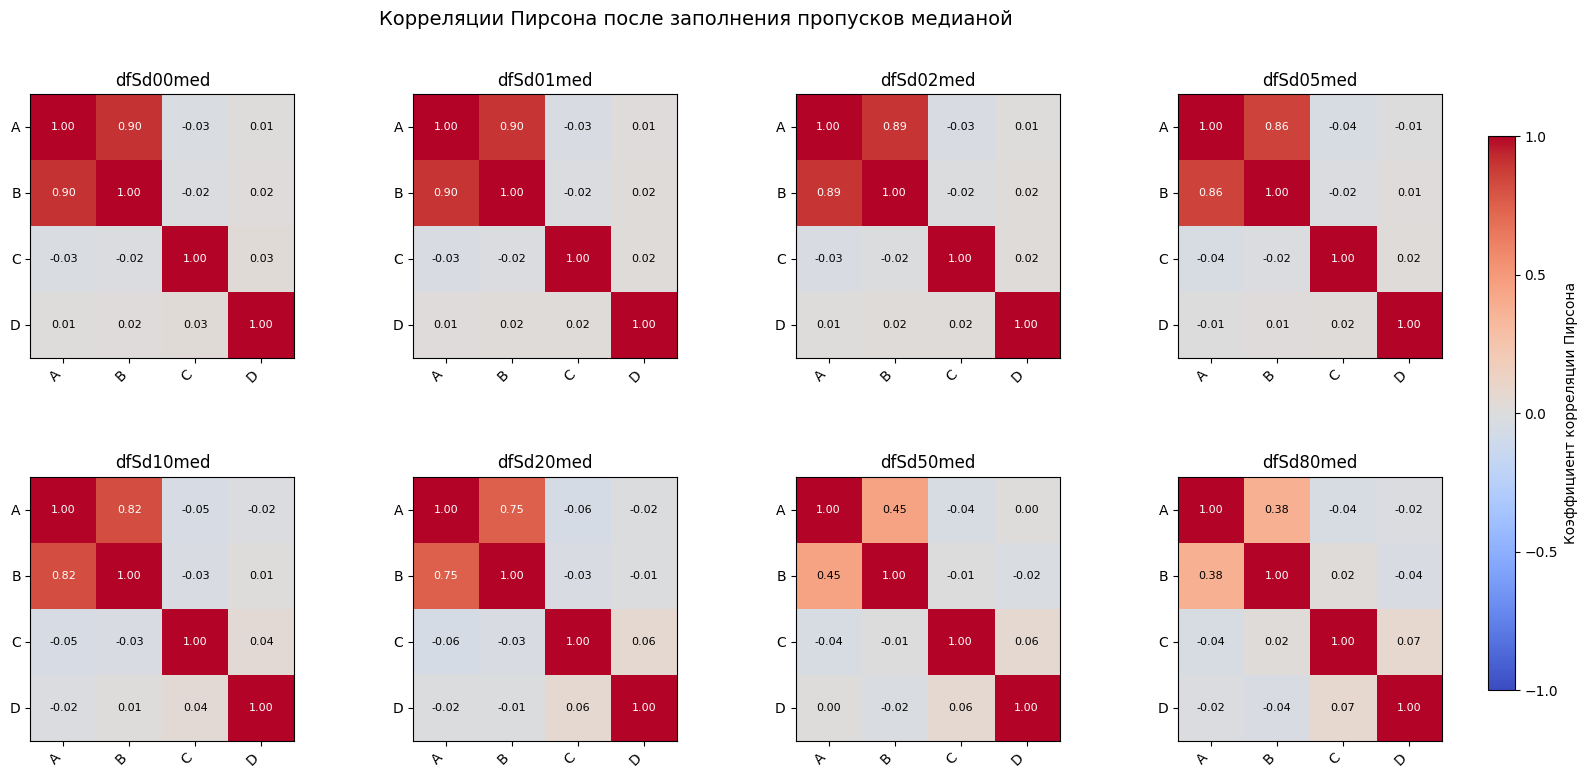

In [12]:
# 1.7

CLASS_COLUMN_MED = "class"
SELECTED_PAIR_MED = ("A", "B")
PANEL_COLUMNS_MED = 4
SCATTER_ALPHA_MED = 0.55
SCATTER_SIZE_MED = 24
SHOW_LEGEND_MED = True

feature_columns_med = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != CLASS_COLUMN_MED
]
x_feature_med, y_feature_med = SELECTED_PAIR_MED

dfSd_med_datasets = {}
imputation_summary_rows = []

for dataset_name, dataset in dfSd_datasets.items():
    imputed = dataset.copy(deep=True)
    missing_before = int(imputed[feature_columns_med].isna().sum().sum())

    for feature in feature_columns_med:
        median_value = imputed[feature].median()
        if pd.isna(median_value):
            median_value = dfS00[feature].median()
        imputed[feature] = imputed[feature].fillna(median_value)

    imputed_name = f"{dataset_name}med"
    dfSd_med_datasets[imputed_name] = imputed
    globals()[imputed_name] = imputed
    imputation_summary_rows.append({
        "Датасет": imputed_name,
        "NaN до заполнения": missing_before,
        "NaN после заполнения": int(imputed[feature_columns_med].isna().sum().sum()),
    })

imputation_summary = pd.DataFrame(imputation_summary_rows)
display(imputation_summary)

class_values_med = dfS00[CLASS_COLUMN_MED].dropna().unique().tolist()
class_colors_med = plt.get_cmap("tab10")
default_markers_med = ["o", "s", "^", "D", "v", "P", "X", "*"]
colors_med = {
    value: class_colors_med(i % 10)
    for i, value in enumerate(class_values_med)
}
markers_med = {
    value: default_markers_med[i % len(default_markers_med)]
    for i, value in enumerate(class_values_med)
}

imputed_items = list(dfSd_med_datasets.items())
n_columns_med = min(PANEL_COLUMNS_MED, len(imputed_items))
n_rows_med = math.ceil(len(imputed_items) / n_columns_med)
fig, axes = plt.subplots(
    n_rows_med,
    n_columns_med,
    figsize=(4.5 * n_columns_med, 4 * n_rows_med),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for ax, (imputed_name, imputed) in zip(axes.flat, imputed_items):
    for class_value in class_values_med:
        class_data = imputed.loc[
            imputed[CLASS_COLUMN_MED] == class_value,
            [x_feature_med, y_feature_med],
        ]
        ax.scatter(
            class_data[x_feature_med],
            class_data[y_feature_med],
            color=colors_med[class_value],
            marker=markers_med[class_value],
            alpha=SCATTER_ALPHA_MED,
            s=SCATTER_SIZE_MED,
            edgecolors="none",
            label=str(class_value),
        )

    percent = int(imputed_name[len("dfSd"):len("dfSd") + 2])
    ax.set_title(f"{imputed_name} ({percent}% добавленных пропусков)")
    ax.grid(True, alpha=0.25)
    if SHOW_LEGEND_MED and ax is axes.flat[0]:
        ax.legend(title=CLASS_COLUMN_MED)

for ax in axes.flat[len(imputed_items):]:
    ax.set_visible(False)

fig.supxlabel(x_feature_med)
fig.supylabel(y_feature_med)
fig.suptitle("Scatterplot после заполнения пропусков медианой", fontsize=14)
fig.tight_layout(rect=(0.03, 0.03, 1, 0.94))
plt.show()
plt.close(fig)

# Heat-map матриц Пирсона для всех dfSdXXmed
heatmap_columns = min(PANEL_COLUMNS_MED, len(imputed_items))
heatmap_rows = math.ceil(len(imputed_items) / heatmap_columns)
fig, heatmap_axes = plt.subplots(
    heatmap_rows,
    heatmap_columns,
    figsize=(4.5 * heatmap_columns, 4.2 * heatmap_rows),
    squeeze=False,
)
cmap_med = plt.get_cmap("coolwarm").copy()
cmap_med.set_bad("#d9d9d9")
heatmap_images = []

for ax, (imputed_name, imputed) in zip(heatmap_axes.flat, imputed_items):
    correlation = imputed[feature_columns_med].corr(method="pearson")
    values = correlation.to_numpy(dtype=float)
    image = ax.imshow(
        np.ma.masked_invalid(values),
        cmap=cmap_med,
        vmin=-1,
        vmax=1,
    )
    heatmap_images.append(image)
    ax.set_xticks(range(len(feature_columns_med)))
    ax.set_xticklabels(feature_columns_med, rotation=45, ha="right")
    ax.set_yticks(range(len(feature_columns_med)))
    ax.set_yticklabels(feature_columns_med)
    ax.set_title(imputed_name)

    for row in range(len(feature_columns_med)):
        for column in range(len(feature_columns_med)):
            value = values[row, column]
            label = "—" if np.isnan(value) else f"{value:.2f}"
            text_color = "white" if np.isfinite(value) and abs(value) >= 0.55 else "black"
            ax.text(
                column, row, label,
                ha="center", va="center",
                color=text_color,
                fontsize=8,
            )

for ax in heatmap_axes.flat[len(imputed_items):]:
    ax.set_visible(False)

fig.subplots_adjust(right=0.92, wspace=0.35, hspace=0.45)
colorbar_axis = fig.add_axes([0.94, 0.17, 0.015, 0.66])
fig.colorbar(
    heatmap_images[-1],
    cax=colorbar_axis,
    ticks=np.linspace(-1, 1, 5),
    label="Коэффициент корреляции Пирсона",
)
fig.suptitle("Корреляции Пирсона после заполнения пропусков медианой", fontsize=14)
plt.show()
plt.close(fig)

c:\conda\envs\osnov\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,Датасет,Метод,NaN после заполнения
0,dfSd20med,med,0
1,dfSd20knn,knn,0
2,dfSd20reg,reg,0
3,dfSd20mice,mice,0


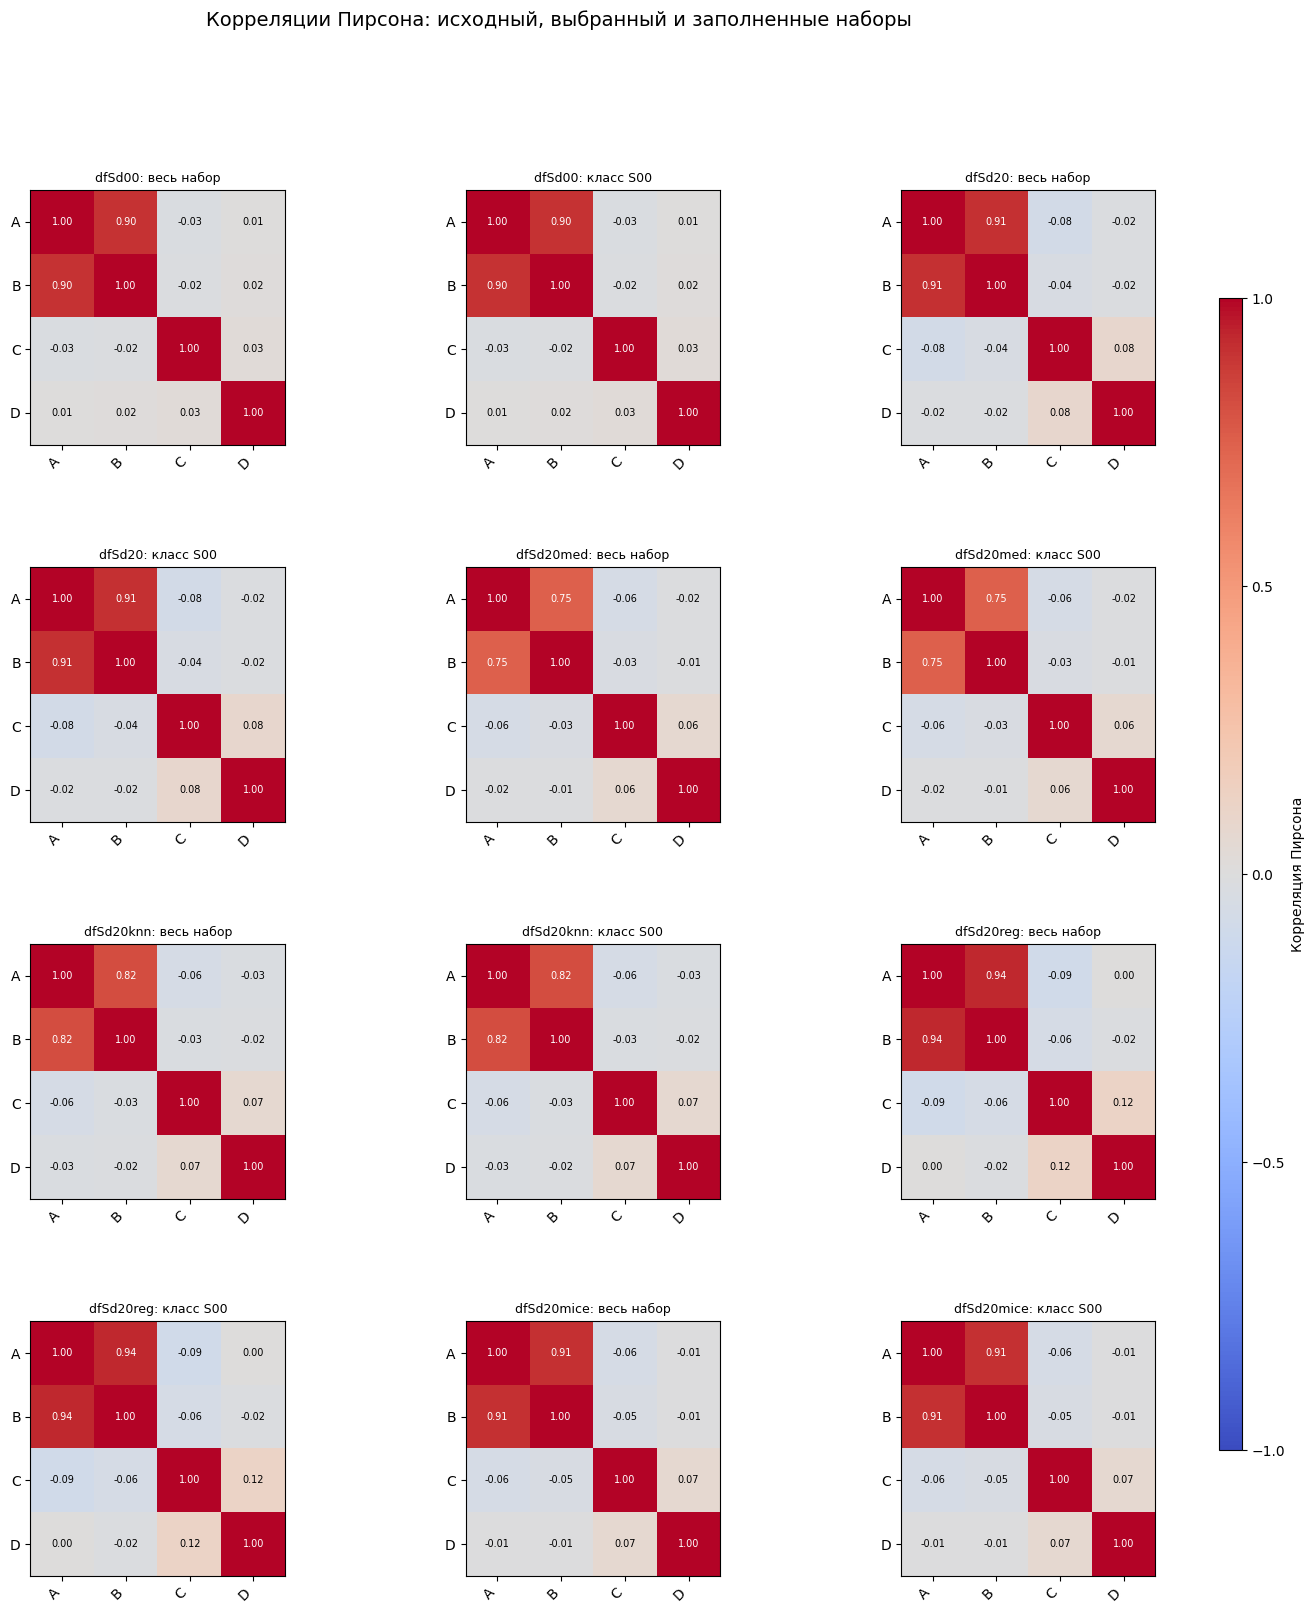

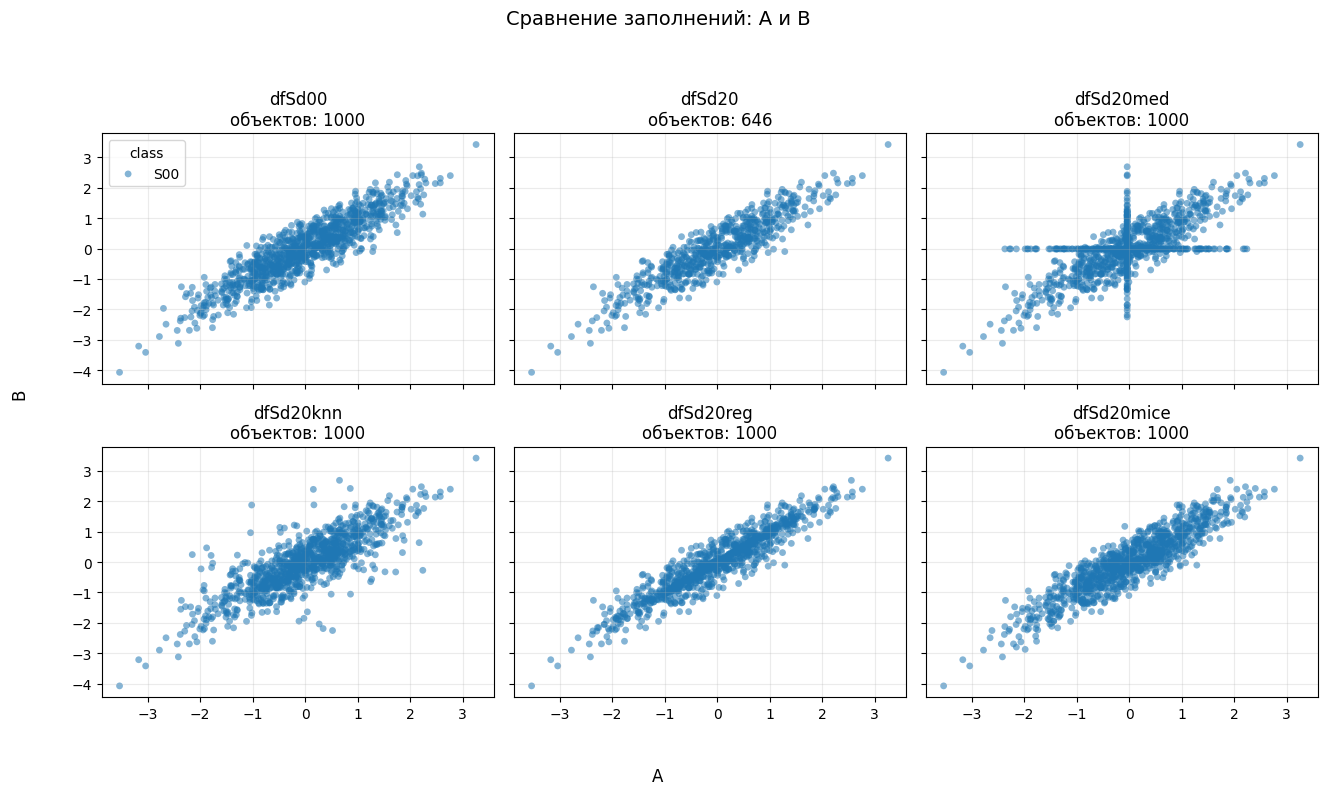

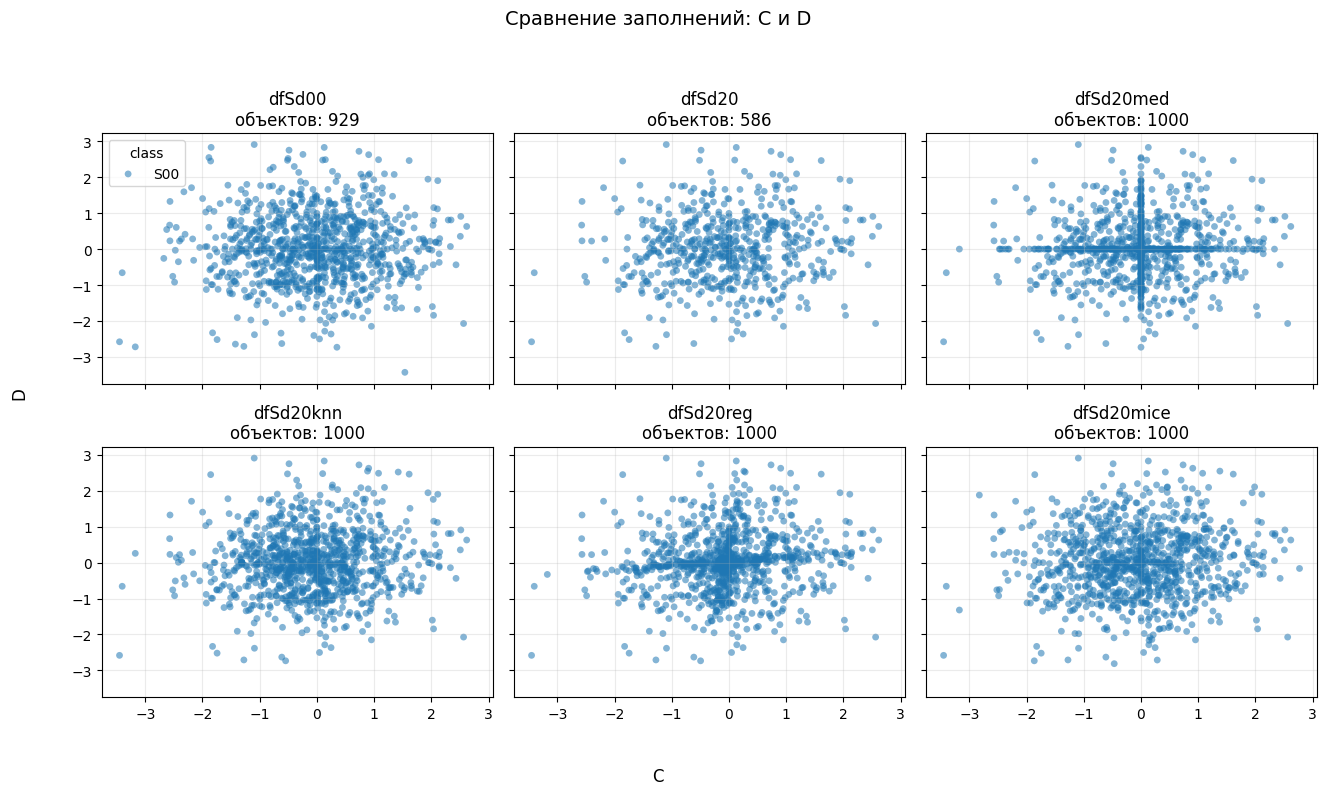

In [13]:
# 1.8

SOURCE_DATASET_NAME = "dfSd20"
SCATTER_PAIRS_18 = [("A", "B"), ("C", "D")]
PANEL_COLUMNS_18 = 3
SCATTER_ALPHA_18 = 0.55
SCATTER_SIZE_18 = 24

if SOURCE_DATASET_NAME not in dfSd_datasets:
    raise KeyError(
        f"{SOURCE_DATASET_NAME} нет в dfSd_datasets; выберите один из "
        f"{list(dfSd_datasets)}."
    )

class_column_18 = "class"
feature_columns_18 = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != class_column_18
]
source_dataset_18 = dfSd_datasets[SOURCE_DATASET_NAME]
source_numeric_18 = source_dataset_18[feature_columns_18]

imputers_18 = {
    "med": SimpleImputer(strategy="median"),
    "knn": KNNImputer(n_neighbors=5, weights="distance"),
    "reg": IterativeImputer(
        estimator=LinearRegression(),
        max_iter=10,
        random_state=1801,
        sample_posterior=False,
    ),
    "mice": IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=1801,
        sample_posterior=True,
    ),
}

dfSdXXname_datasets = {}
imputation_summary_18 = []

for method_name, imputer in imputers_18.items():
    imputed_values = imputer.fit_transform(source_numeric_18)
    if imputed_values.shape[1] != len(feature_columns_18):
        raise ValueError(
            f"Метод {method_name} вернул неожиданное число признаков."
        )

    imputed_dataset = source_dataset_18.copy(deep=True)
    imputed_dataset[feature_columns_18] = imputed_values
    output_name = f"{SOURCE_DATASET_NAME}{method_name}"
    dfSdXXname_datasets[output_name] = imputed_dataset
    globals()[output_name] = imputed_dataset
    imputation_summary_18.append({
        "Датасет": output_name,
        "Метод": method_name,
        "NaN после заполнения": int(
            imputed_dataset[feature_columns_18].isna().sum().sum()
        ),
    })

display(pd.DataFrame(imputation_summary_18))

comparison_datasets_18 = {"dfSd00": dfSd00}
comparison_datasets_18[SOURCE_DATASET_NAME] = source_dataset_18
comparison_datasets_18.update(dfSdXXname_datasets)
comparison_items_18 = list(comparison_datasets_18.items())

# Heat-map коэффициента Пирсона для всего набора и каждого класса.
heatmap_records_18 = []
class_values_18 = dfSd00[class_column_18].dropna().unique().tolist()
for dataset_name, dataset in comparison_items_18:
    heatmap_records_18.append((f"{dataset_name}: весь набор", dataset))
    for class_value in class_values_18:
        class_data = dataset.loc[dataset[class_column_18] == class_value]
        heatmap_records_18.append(
            (f"{dataset_name}: класс {class_value}", class_data)
        )

heatmap_columns_18 = 3
heatmap_rows_18 = math.ceil(len(heatmap_records_18) / heatmap_columns_18)
fig, heatmap_axes_18 = plt.subplots(
    heatmap_rows_18,
    heatmap_columns_18,
    figsize=(5 * heatmap_columns_18, 4.5 * heatmap_rows_18),
    squeeze=False,
)
cmap_18 = plt.get_cmap("coolwarm").copy()
cmap_18.set_bad("#d9d9d9")
images_18 = []

for ax, (dataset_title, dataset) in zip(
    heatmap_axes_18.flat, heatmap_records_18
):
    correlation = dataset[feature_columns_18].corr(method="pearson")
    values = correlation.to_numpy(dtype=float)
    image = ax.imshow(
        np.ma.masked_invalid(values),
        cmap=cmap_18,
        vmin=-1,
        vmax=1,
    )
    images_18.append(image)
    ax.set_xticks(range(len(feature_columns_18)))
    ax.set_xticklabels(feature_columns_18, rotation=45, ha="right")
    ax.set_yticks(range(len(feature_columns_18)))
    ax.set_yticklabels(feature_columns_18)
    ax.set_title(dataset_title, fontsize=9)
    ax.set_aspect("equal")

    for row in range(len(feature_columns_18)):
        for column in range(len(feature_columns_18)):
            value = values[row, column]
            label = "—" if np.isnan(value) else f"{value:.2f}"
            text_color = "white" if np.isfinite(value) and abs(value) >= 0.55 else "black"
            ax.text(
                column, row, label,
                ha="center", va="center",
                color=text_color, fontsize=7,
            )

for ax in heatmap_axes_18.flat[len(heatmap_records_18):]:
    ax.set_visible(False)

fig.subplots_adjust(right=0.92, wspace=0.35, hspace=0.48)
colorbar_axis_18 = fig.add_axes([0.94, 0.18, 0.015, 0.64])
fig.colorbar(
    images_18[-1],
    cax=colorbar_axis_18,
    ticks=np.linspace(-1, 1, 5),
    label="Корреляция Пирсона",
)
fig.suptitle("Корреляции Пирсона: исходный, выбранный и заполненные наборы", fontsize=14)
plt.show()
plt.close(fig)

class_values_18 = dfSd00[class_column_18].dropna().unique().tolist()
palette_18 = plt.get_cmap("tab10")
markers_18 = ["o", "s", "^", "D", "v", "P", "X", "*"]
colors_by_class_18 = {
    value: palette_18(i % 10) for i, value in enumerate(class_values_18)
}
markers_by_class_18 = {
    value: markers_18[i % len(markers_18)]
    for i, value in enumerate(class_values_18)
}

for x_feature, y_feature in SCATTER_PAIRS_18:
    if x_feature not in feature_columns_18 or y_feature not in feature_columns_18:
        raise ValueError(f"Пара {(x_feature, y_feature)} содержит неизвестный признак.")

    panel_columns = min(PANEL_COLUMNS_18, len(comparison_items_18))
    panel_rows = math.ceil(len(comparison_items_18) / panel_columns)
    fig, axes = plt.subplots(
        panel_rows,
        panel_columns,
        figsize=(4.5 * panel_columns, 4 * panel_rows),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for ax, (dataset_name, dataset) in zip(
        axes.flat, comparison_items_18
    ):
        valid_pair = dataset[[x_feature, y_feature]].notna().all(axis=1)
        n_valid = int(valid_pair.sum())
        for class_value in class_values_18:
            class_mask = valid_pair & dataset[class_column_18].eq(class_value)
            class_data = dataset.loc[class_mask, [x_feature, y_feature]]
            ax.scatter(
                class_data[x_feature],
                class_data[y_feature],
                color=colors_by_class_18[class_value],
                marker=markers_by_class_18[class_value],
                alpha=SCATTER_ALPHA_18,
                s=SCATTER_SIZE_18,
                edgecolors="none",
                label=str(class_value),
            )
        ax.set_title(f"{dataset_name}\nобъектов: {n_valid}")
        ax.grid(True, alpha=0.25)
        if ax is axes.flat[0]:
            ax.legend(title=class_column_18)

    for ax in axes.flat[len(comparison_items_18):]:
        ax.set_visible(False)

    fig.supxlabel(x_feature)
    fig.supylabel(y_feature)
    fig.suptitle(f"Сравнение заполнений: {x_feature} и {y_feature}", fontsize=14)
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.94))
    plt.show()
    plt.close(fig)

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


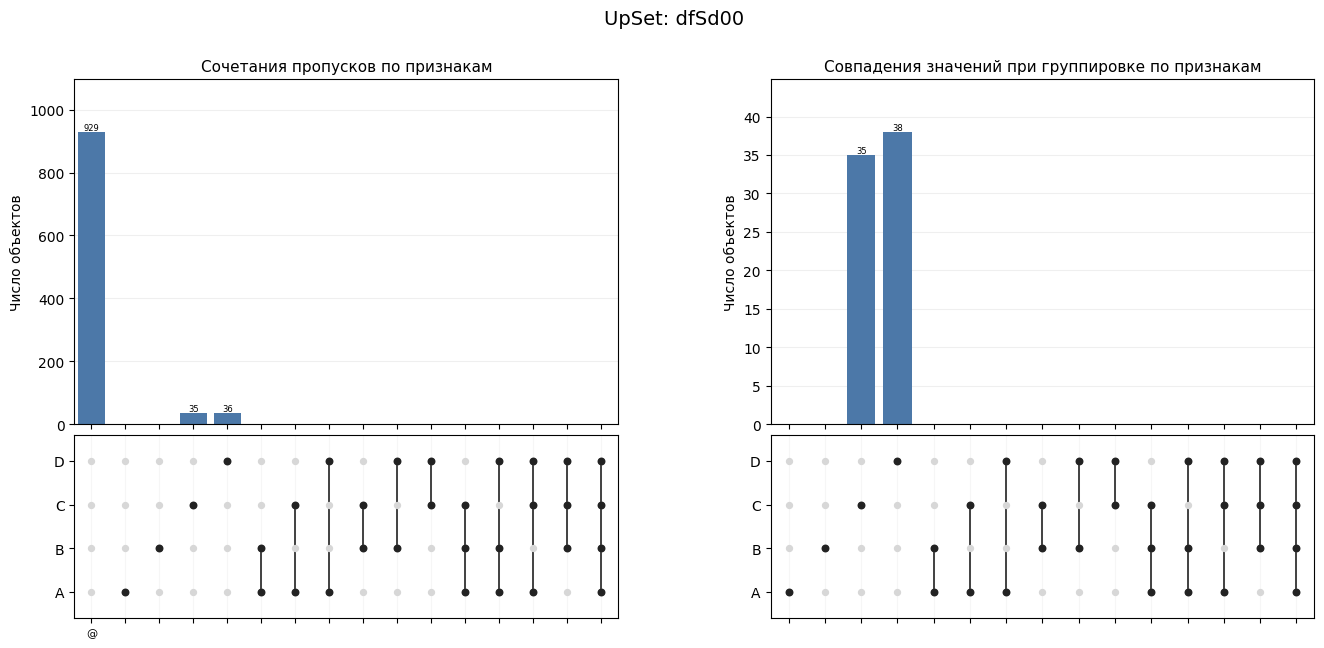

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


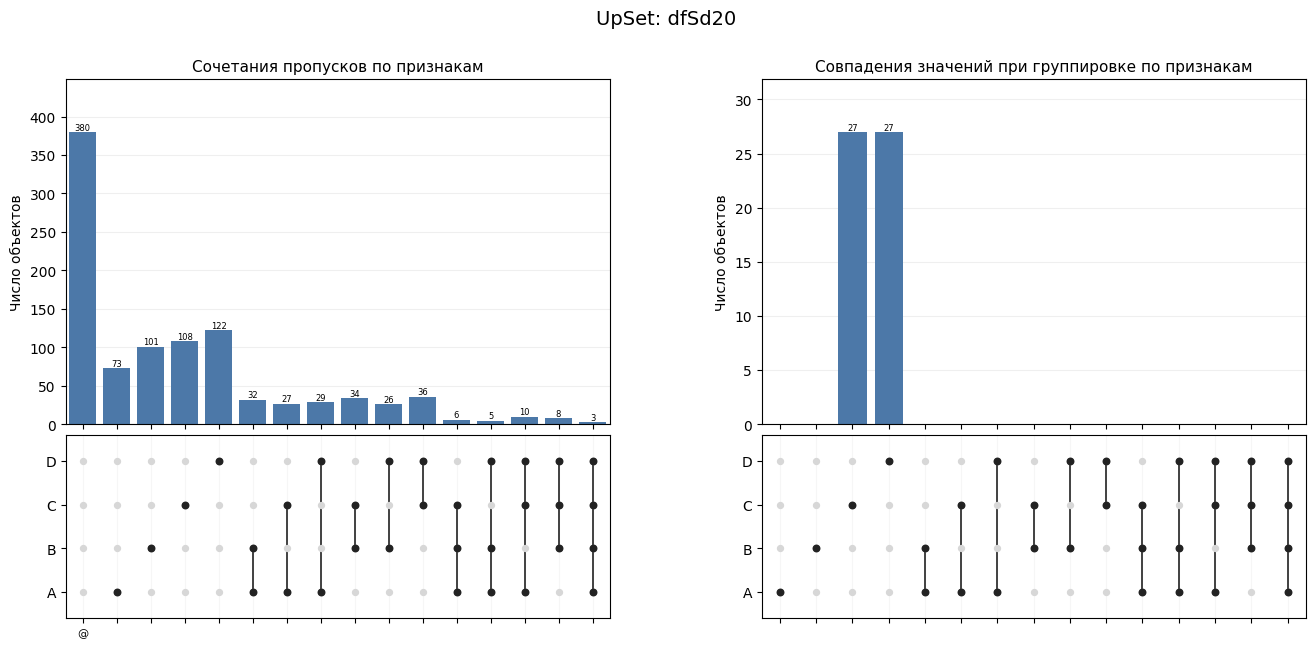

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


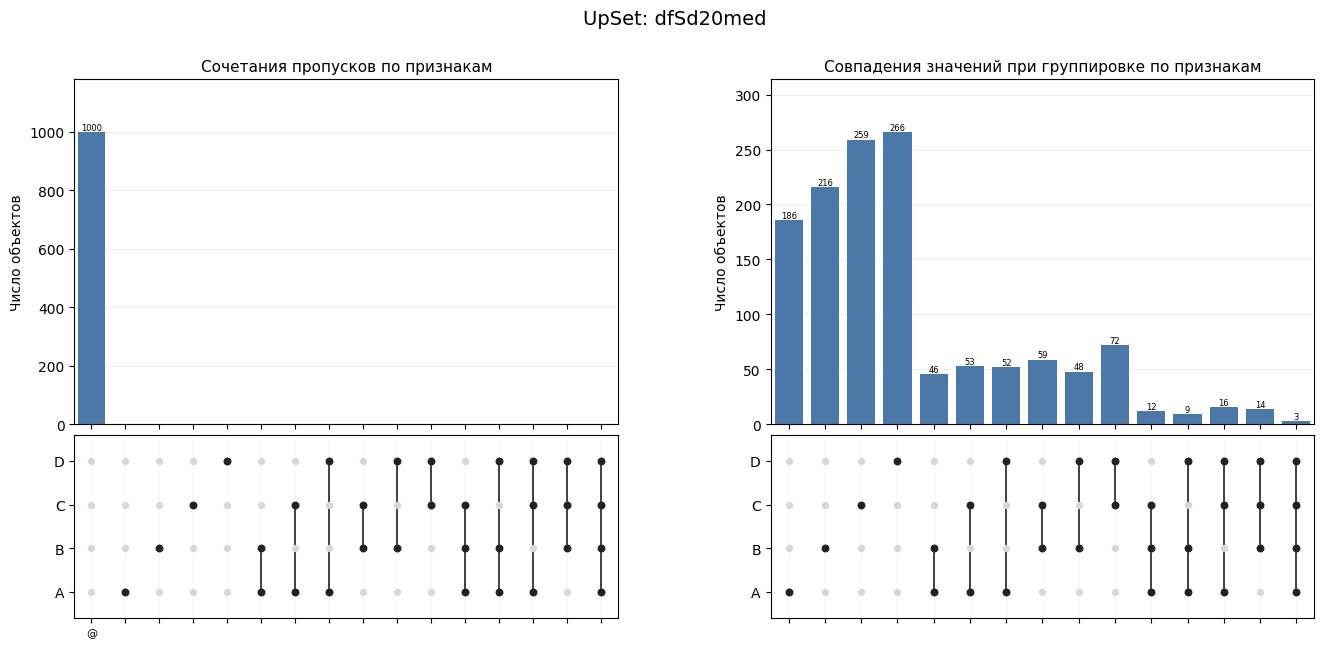

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


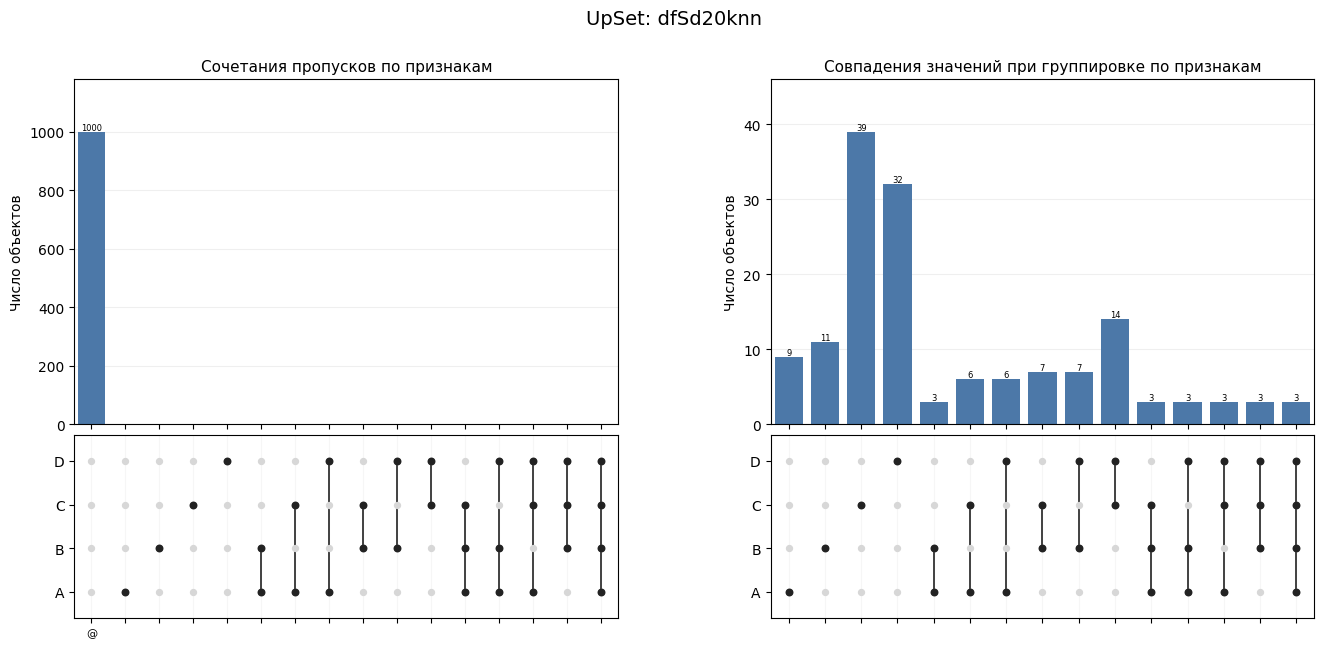

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


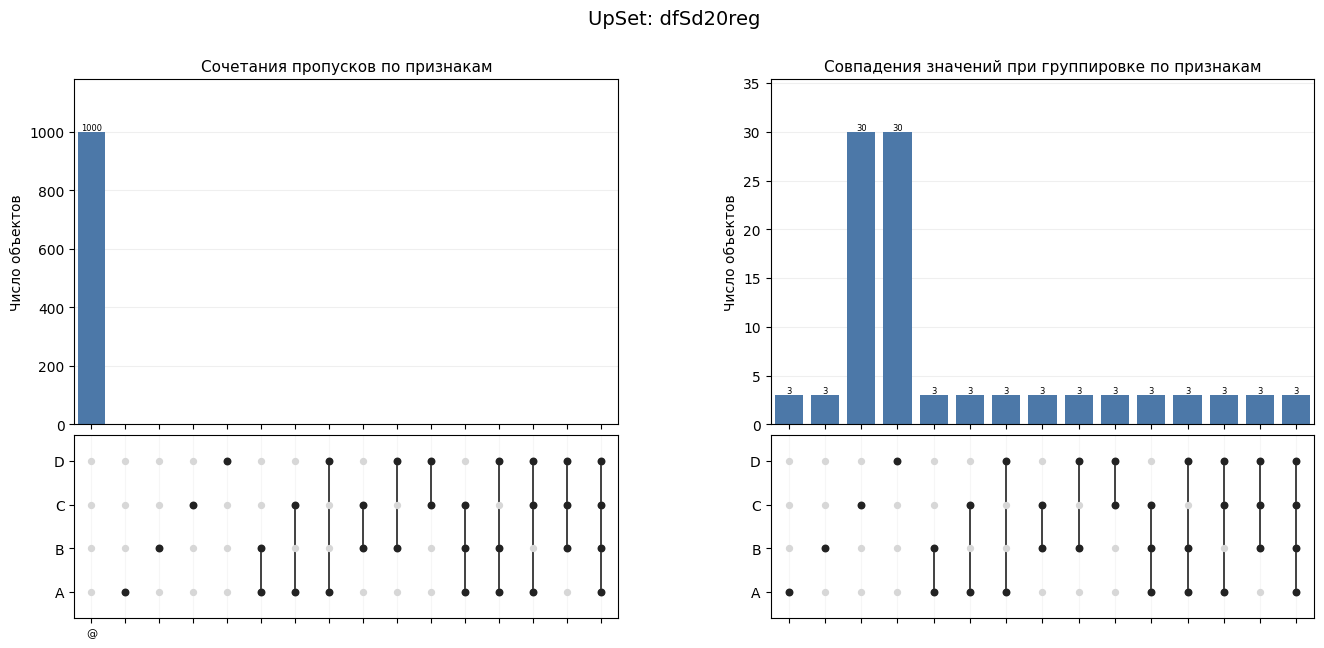

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\3279528379.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


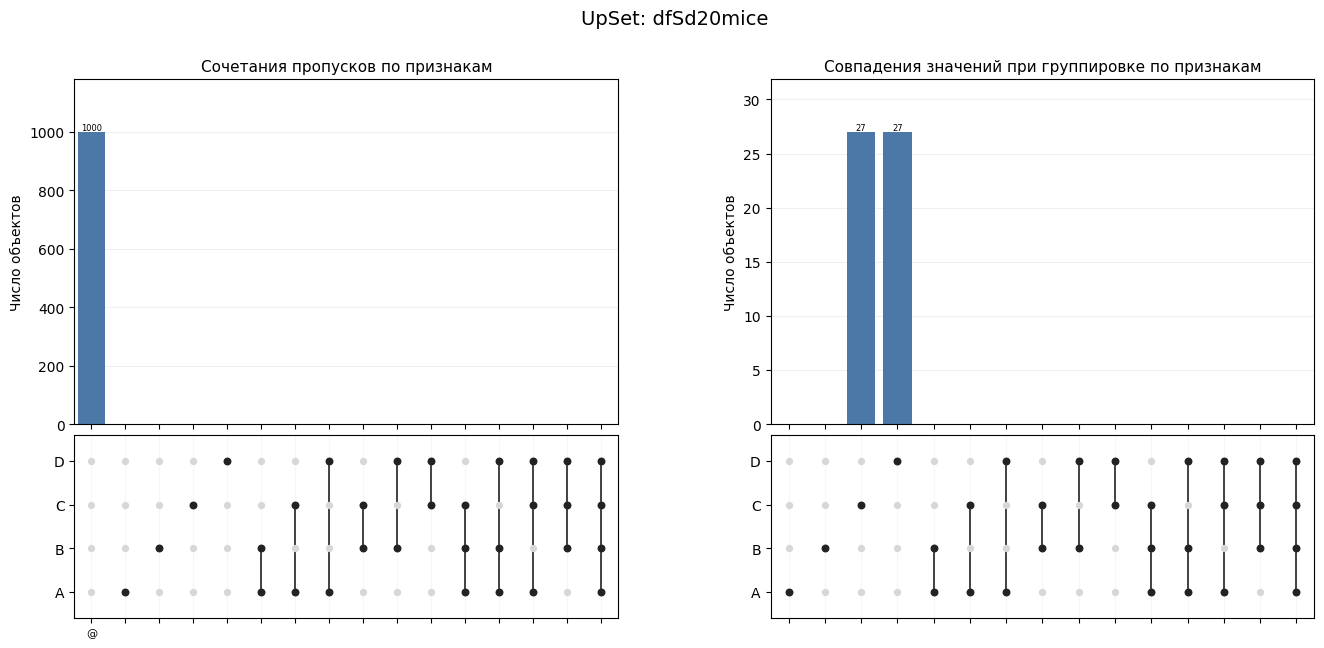

In [14]:
# 1.9

upset_feature_columns = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != "class"
]
upset_datasets = {"dfSd00": dfSd00}
upset_datasets[SOURCE_DATASET_NAME] = dfSd_datasets[SOURCE_DATASET_NAME]
upset_datasets.update(dfSdXXname_datasets)

# Все сочетания признаков 
all_feature_subsets = [
    subset
    for size in range(1, len(upset_feature_columns) + 1)
    for subset in itertools.combinations(upset_feature_columns, size)
]
all_missing_patterns = [()] + all_feature_subsets


def get_missing_pattern_counts(dataset):
    counts = {pattern: 0 for pattern in all_missing_patterns}
    missing_flags = dataset[upset_feature_columns].isna().to_numpy()
    for row in missing_flags:
        pattern = tuple(
            feature
            for feature, is_missing in zip(upset_feature_columns, row)
            if is_missing
        )
        counts[pattern] += 1
    return counts


def get_duplicate_object_counts(dataset):
    counts = {}
    for subset in all_feature_subsets:
        complete_rows = dataset[list(subset)].dropna()
        group_sizes = complete_rows.groupby(
            list(subset), dropna=False, sort=False
        ).size()
        counts[subset] = int(group_sizes[group_sizes > 1].sum())
    return counts


def draw_upset_panel(fig, grid_cell, feature_names, patterns, counts, title):
    inner_grid = grid_cell.subgridspec(
        2, 1, height_ratios=(3.2, 1.7), hspace=0.04
    )
    bar_ax = fig.add_subplot(inner_grid[0])
    matrix_ax = fig.add_subplot(inner_grid[1], sharex=bar_ax)

    positions = np.arange(len(patterns))
    bar_values = [counts[pattern] for pattern in patterns]
    bars = bar_ax.bar(positions, bar_values, color="#4c78a8", width=0.78)
    bar_ax.set_title(title, fontsize=11)
    bar_ax.set_ylabel("Число объектов")
    bar_ax.tick_params(axis="x", labelbottom=False)
    bar_ax.grid(axis="y", alpha=0.2)
    bar_ax.set_axisbelow(True)

    max_value = max(bar_values, default=0)
    bar_ax.set_ylim(0, max_value * 1.18 if max_value > 0 else 1)
    for bar, value in zip(bars, bar_values):
        if value > 0:
            bar_ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                str(value),
                ha="center",
                va="bottom",
                fontsize=6,
            )

    feature_positions = {feature: i for i, feature in enumerate(feature_names)}
    for x_position, pattern in zip(positions, patterns):
        selected_positions = [feature_positions[f] for f in pattern]
        matrix_ax.scatter(
            [x_position] * len(feature_names),
            range(len(feature_names)),
            color="#d7d7d7",
            s=18,
            zorder=2,
        )
        if len(selected_positions) >= 2:
            matrix_ax.plot(
                [x_position, x_position],
                [min(selected_positions), max(selected_positions)],
                color="#222222",
                linewidth=1.2,
                zorder=1,
            )
        if selected_positions:
            matrix_ax.scatter(
                [x_position] * len(selected_positions),
                selected_positions,
                color="#222222",
                s=22,
                zorder=3,
            )

    matrix_ax.set_yticks(range(len(feature_names)))
    matrix_ax.set_yticklabels(feature_names)
    matrix_ax.set_xticks(positions)
    # @ помечает строки без пропусков; остальные сочетания задаёт матрица точек.
    matrix_ax.set_xticklabels(
        ["@" if not pattern else "" for pattern in patterns],
        fontsize=8,
    )
    matrix_ax.set_ylim(-0.6, len(feature_names) - 0.4)
    matrix_ax.set_xlim(-0.5, len(patterns) - 0.5)
    matrix_ax.grid(axis="x", alpha=0.1)
    matrix_ax.set_axisbelow(True)
    return bar_ax, matrix_ax


for dataset_name, dataset in upset_datasets.items():
    missing_counts = get_missing_pattern_counts(dataset)
    duplicate_counts = get_duplicate_object_counts(dataset)

    # Фиксированный порядок сочетаний облегчает сравнение датасетов.
    patterns_missing = all_missing_patterns
    patterns_duplicates = all_feature_subsets

    fig = plt.figure(figsize=(16, 7))
    outer_grid = fig.add_gridspec(1, 2, wspace=0.28)
    draw_upset_panel(
        fig,
        outer_grid[0],
        upset_feature_columns,
        patterns_missing,
        missing_counts,
        "Сочетания пропусков по признакам",
    )
    draw_upset_panel(
        fig,
        outer_grid[1],
        upset_feature_columns,
        patterns_duplicates,
        duplicate_counts,
        "Совпадения значений при группировке по признакам",
    )
    fig.suptitle(f"UpSet: {dataset_name}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
    plt.close(fig)

,Признак,Медиана исходного dfS00,Новых пропусков,Всего NaN после удаления
0,C,0.0,470,505
1,D,0.0,463,499


c:\conda\envs\osnov\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,Датасет,NaN после заполнения
0,dfMNARmed,0
1,dfMNARknn,0
2,dfMNARreg,0
3,dfMNARmice,0


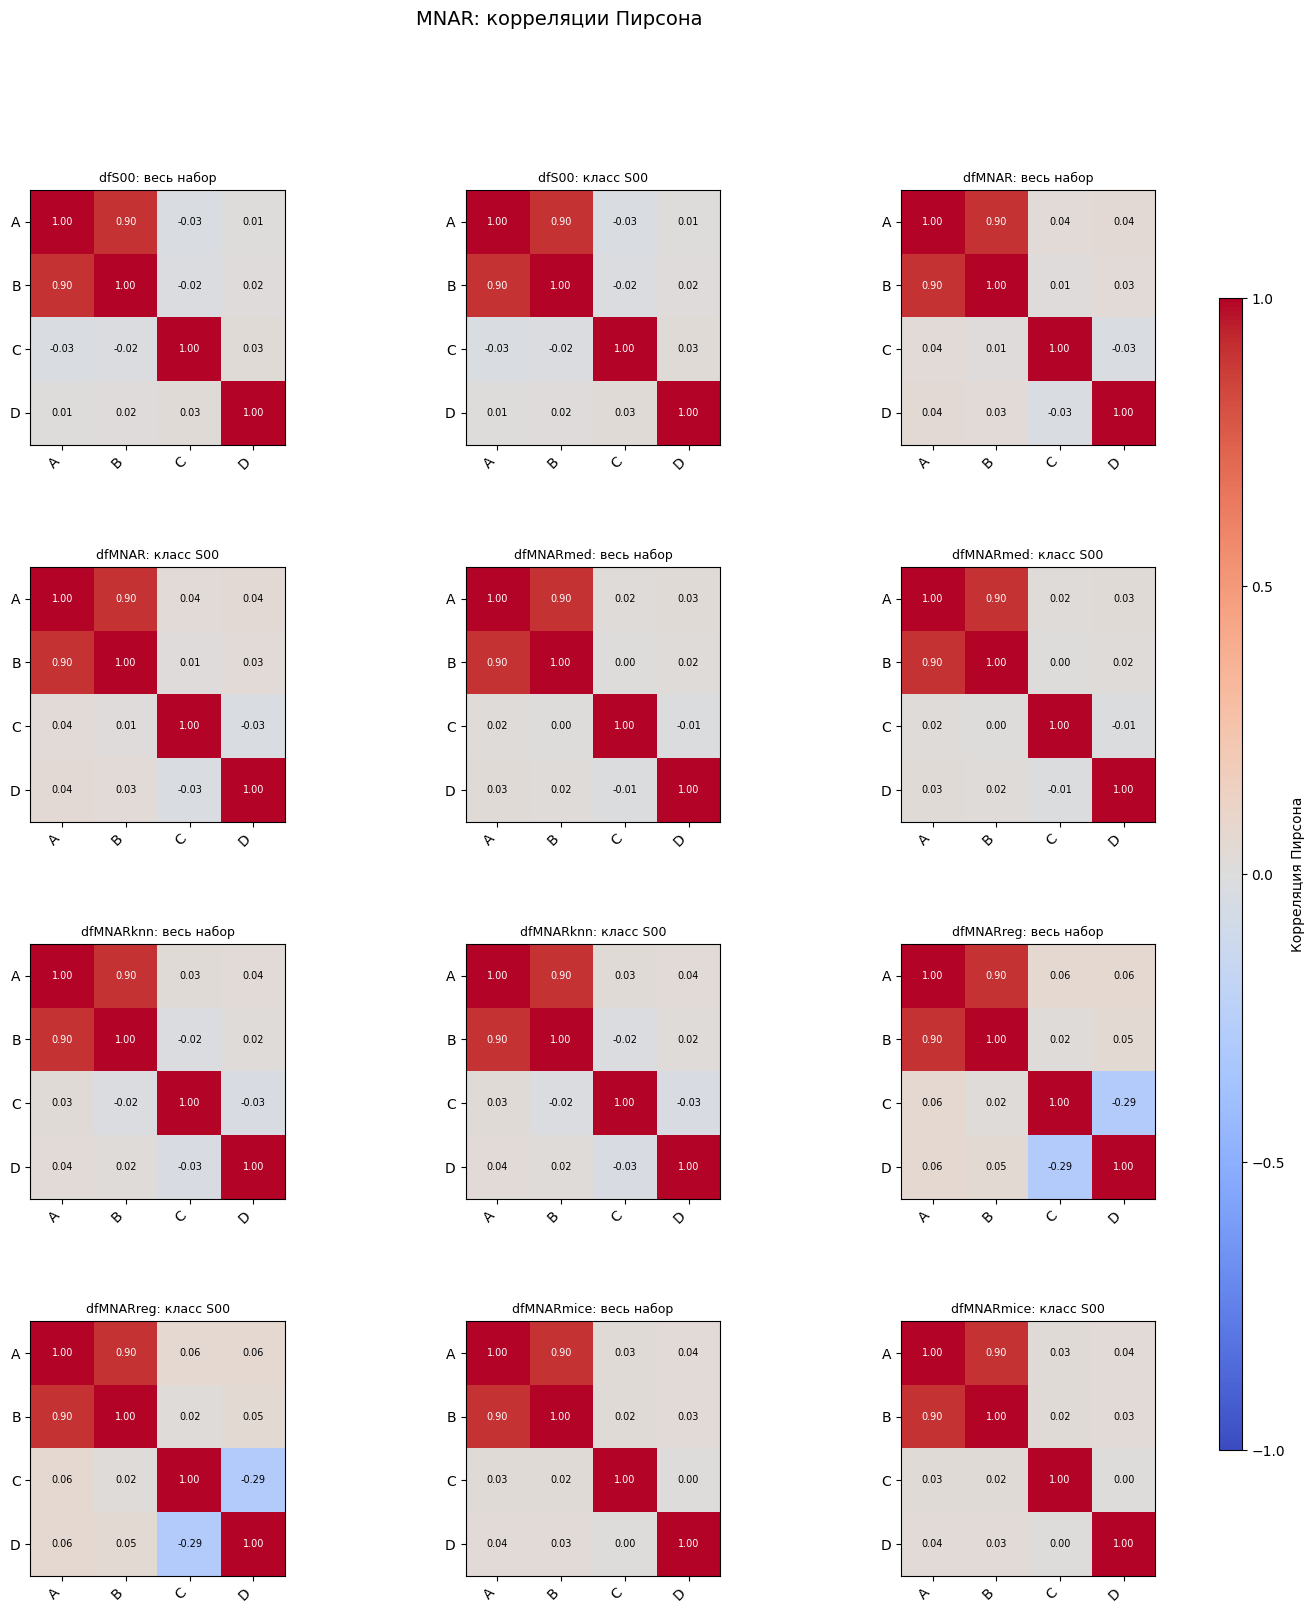

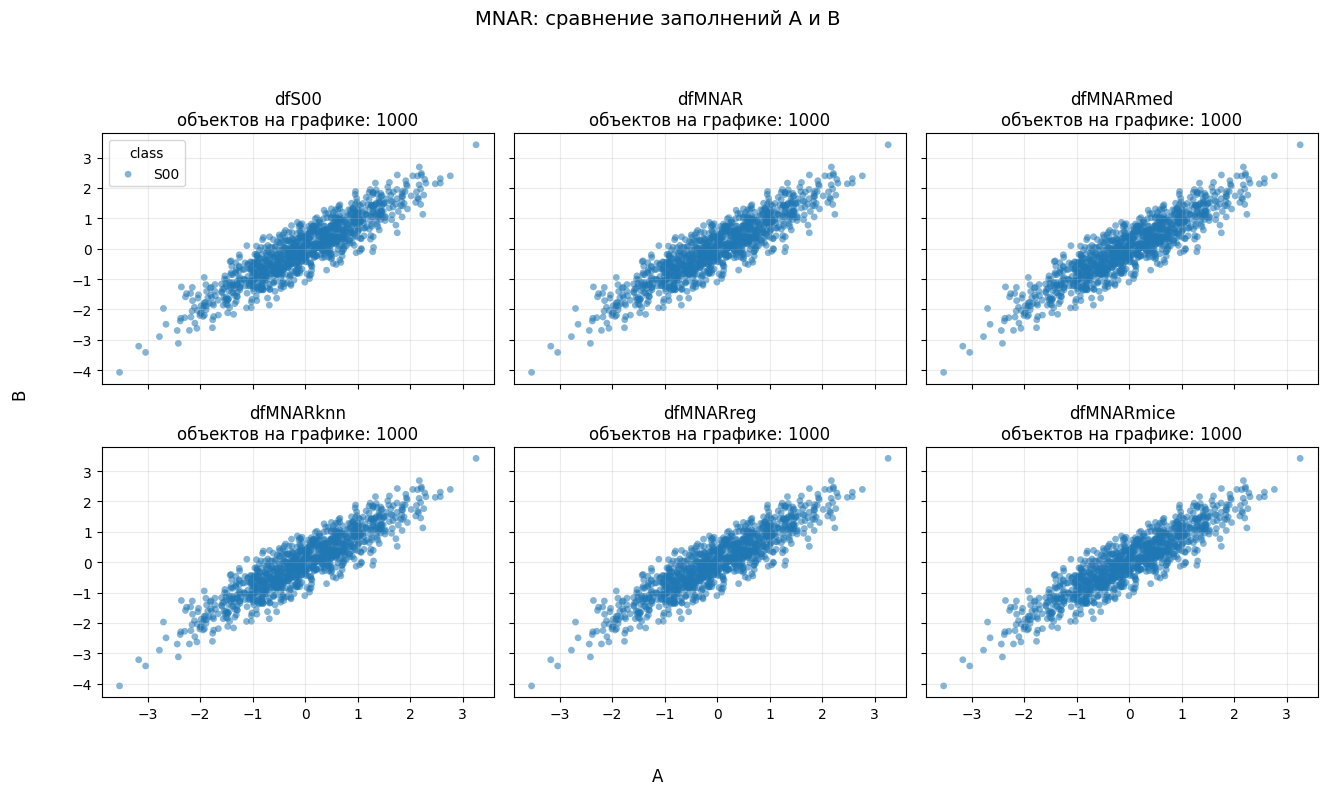

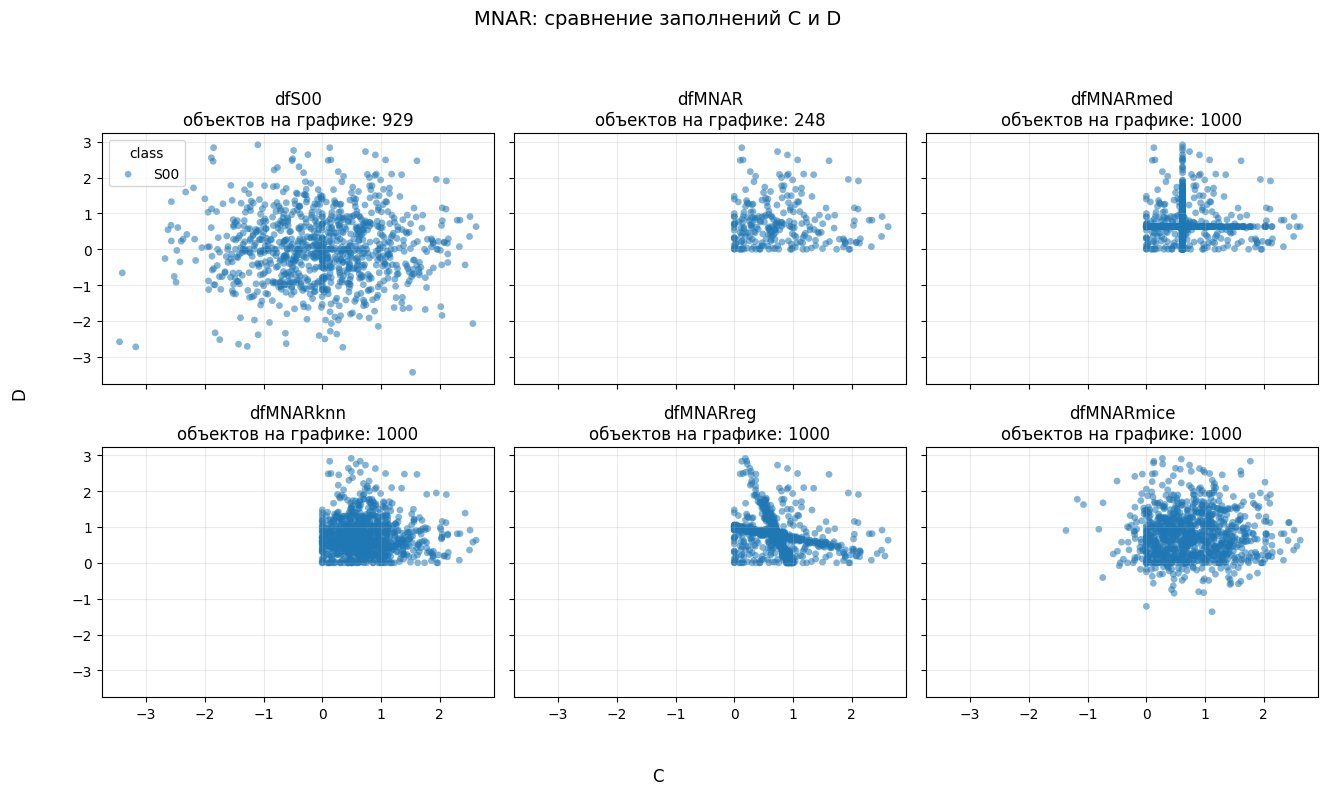

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


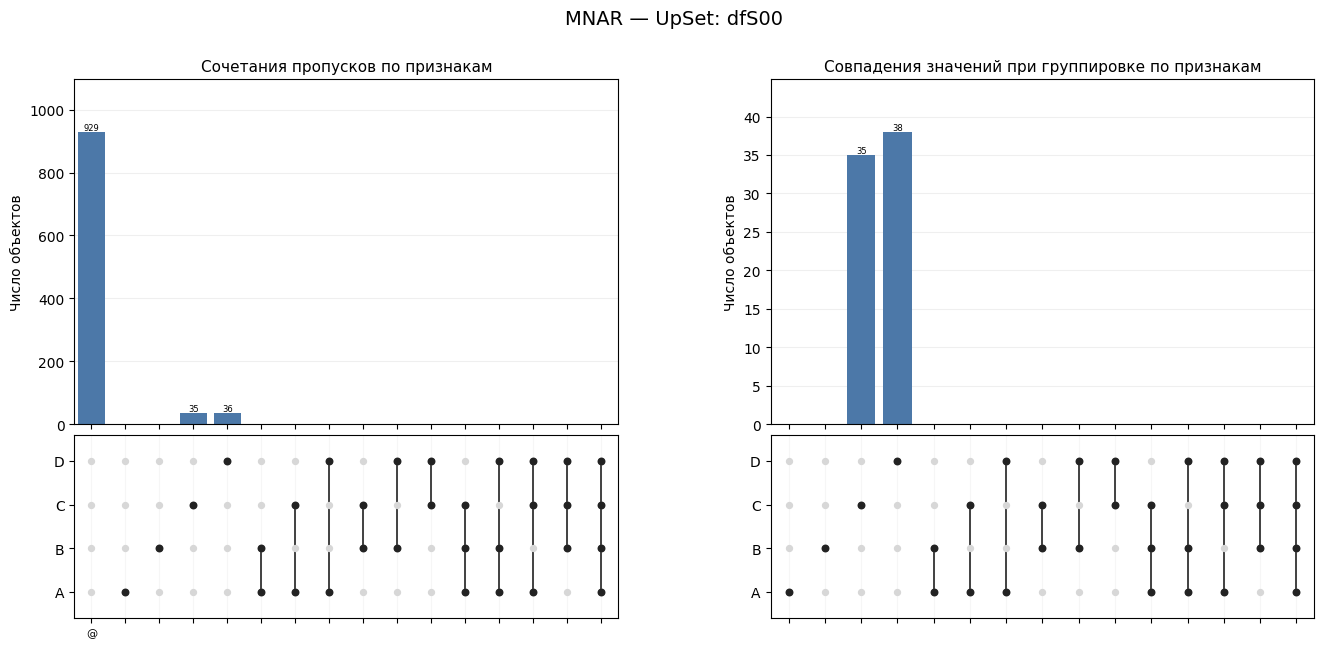

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


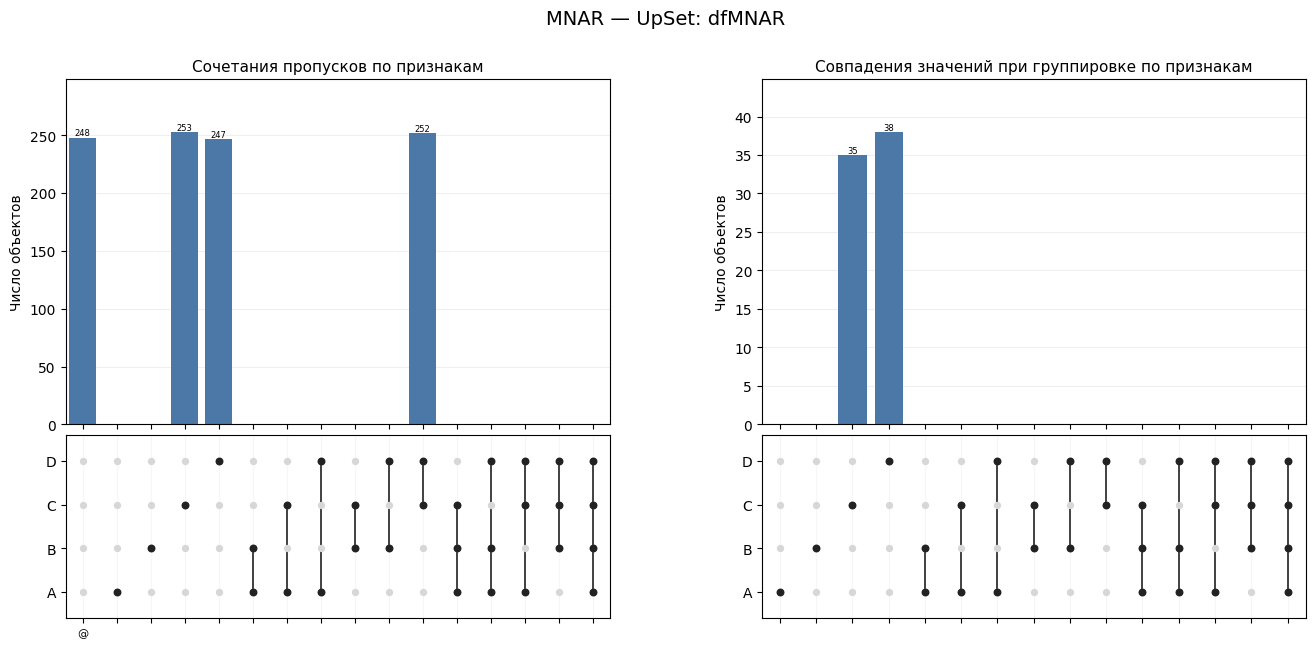

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


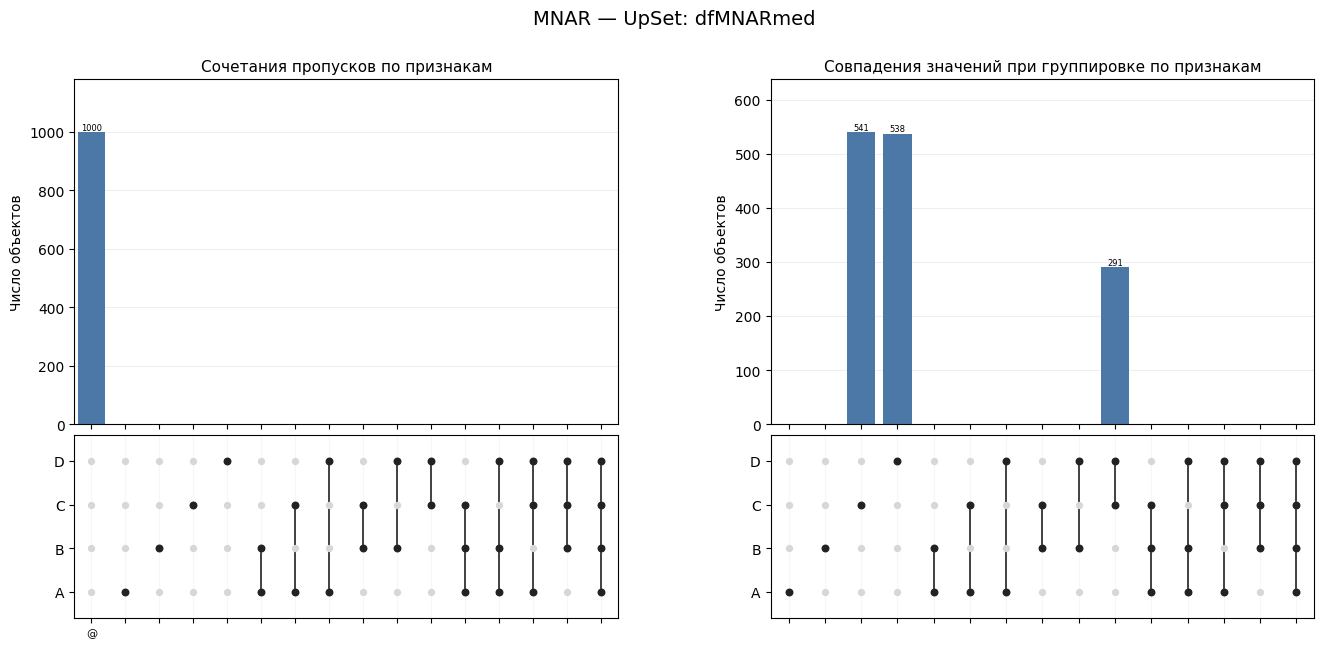

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


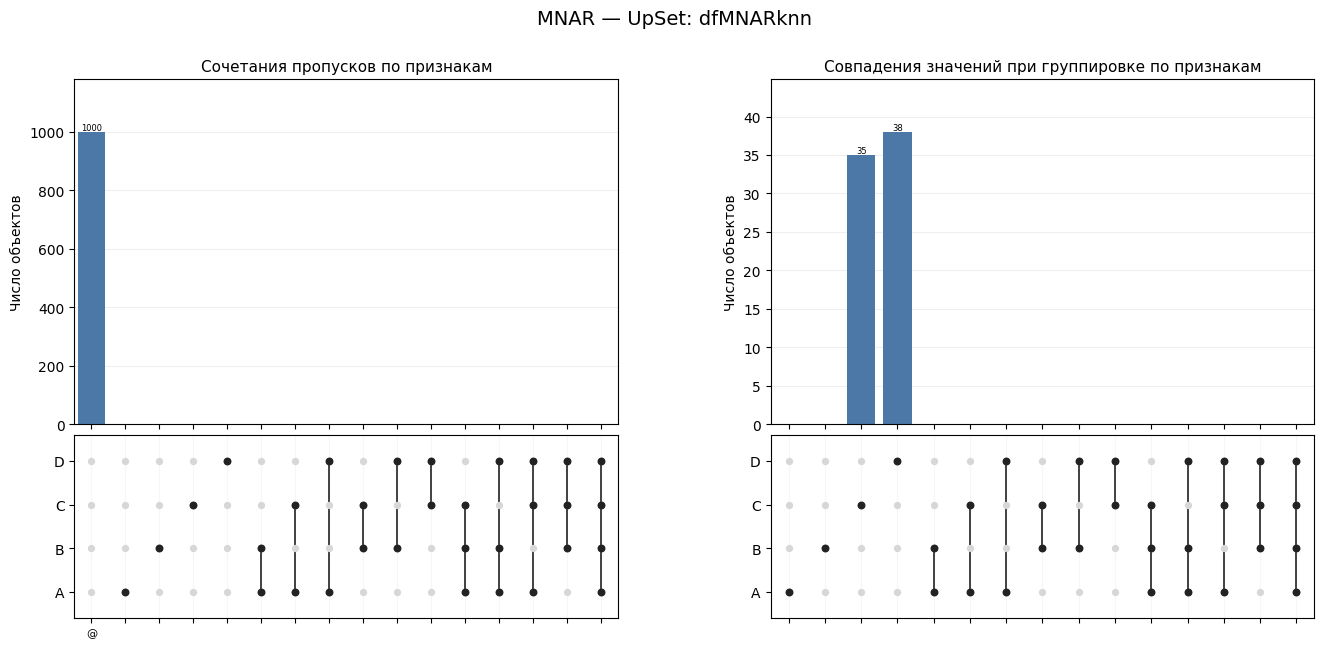

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


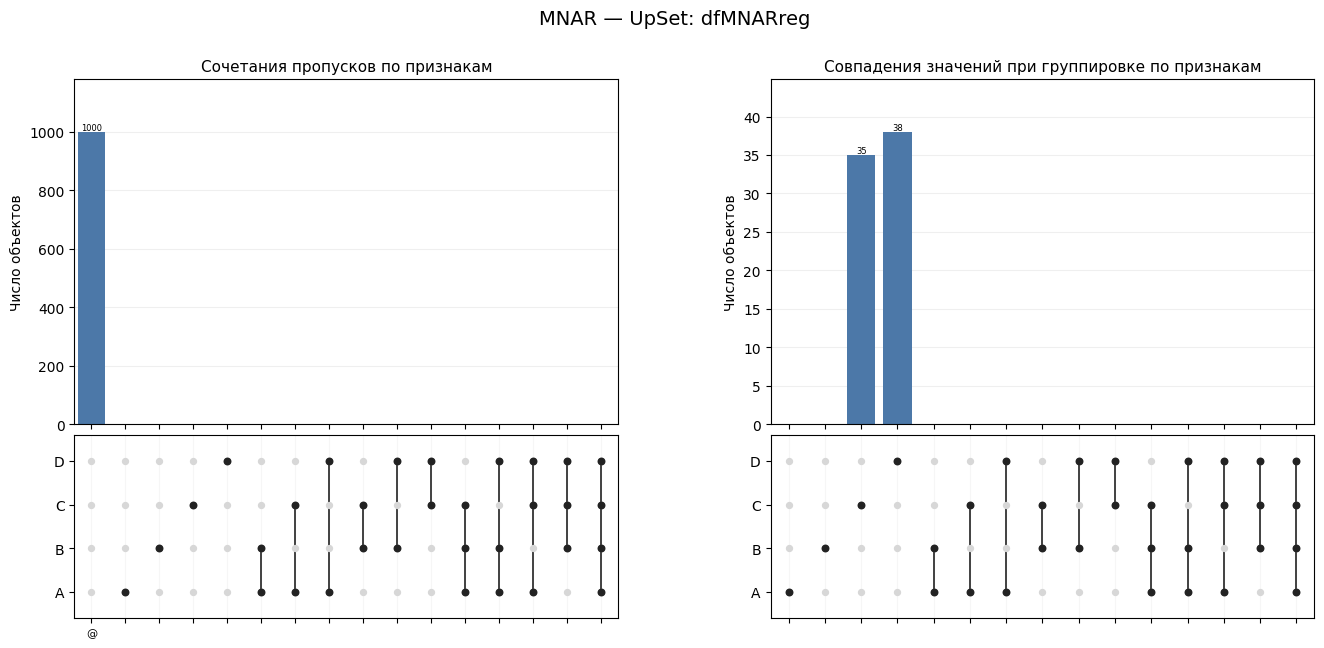

C:\Users\Алексей\AppData\Local\Temp\ipykernel_21324\1712239122.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.94))


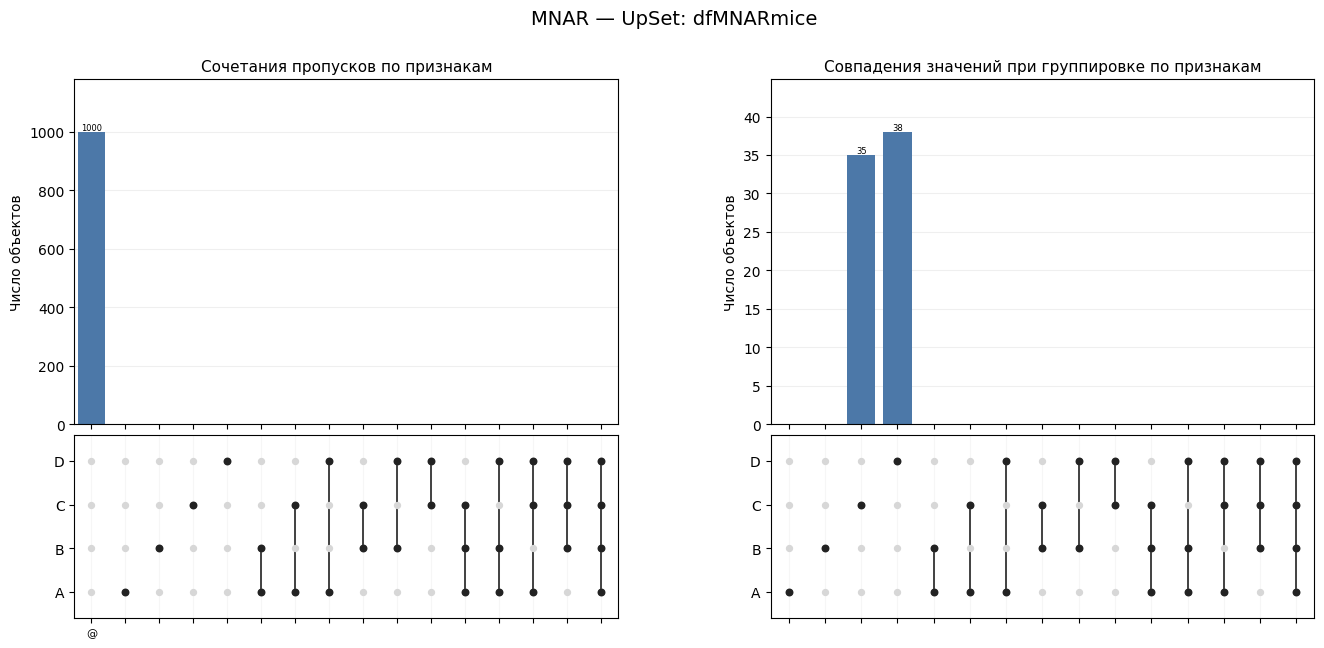

In [15]:
# 1.10

MNAR_FEATURES = ["C", "D"]
MNAR_THRESHOLDS = {
    feature: dfS00[feature].median()
    for feature in MNAR_FEATURES
}

dfMNAR = dfS00.copy(deep=True)
mnar_summary_rows = []
for feature in MNAR_FEATURES:
    below_median = dfMNAR[feature] < MNAR_THRESHOLDS[feature]
    n_removed = int(below_median.sum())
    dfMNAR.loc[below_median, feature] = np.nan
    mnar_summary_rows.append({
        "Признак": feature,
        "Медиана исходного dfS00": MNAR_THRESHOLDS[feature],
        "Новых пропусков": n_removed,
        "Всего NaN после удаления": int(dfMNAR[feature].isna().sum()),
    })

display(pd.DataFrame(mnar_summary_rows))

mnar_features = [
    column for column in dfS00.select_dtypes(include="number").columns
    if column != "class"
]
mnar_imputers = {
    "med": SimpleImputer(strategy="median"),
    "knn": KNNImputer(n_neighbors=5, weights="distance"),
    "reg": IterativeImputer(
        estimator=LinearRegression(),
        max_iter=10,
        random_state=1810,
        sample_posterior=False,
    ),
    "mice": IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=1810,
        sample_posterior=True,
    ),
}

dfMNAR_methods = {}
mnar_imputation_summary = []
for method_name, imputer in mnar_imputers.items():
    filled_values = imputer.fit_transform(dfMNAR[mnar_features])
    filled = dfMNAR.copy(deep=True)
    filled[mnar_features] = filled_values
    output_name = f"dfMNAR{method_name}"
    dfMNAR_methods[output_name] = filled
    globals()[output_name] = filled
    mnar_imputation_summary.append({
        "Датасет": output_name,
        "NaN после заполнения": int(filled[mnar_features].isna().sum().sum()),
    })

display(pd.DataFrame(mnar_imputation_summary))

mnar_comparison = {"dfS00": dfS00, "dfMNAR": dfMNAR}
mnar_comparison.update(dfMNAR_methods)
mnar_comparison_items = list(mnar_comparison.items())
mnar_classes = dfS00["class"].dropna().unique().tolist()

mnar_heatmap_records = []
for dataset_name, dataset in mnar_comparison_items:
    mnar_heatmap_records.append((f"{dataset_name}: весь набор", dataset))
    for class_value in mnar_classes:
        class_data = dataset.loc[dataset["class"] == class_value]
        mnar_heatmap_records.append(
            (f"{dataset_name}: класс {class_value}", class_data)
        )

mnar_heatmap_columns = 3
mnar_heatmap_rows = math.ceil(
    len(mnar_heatmap_records) / mnar_heatmap_columns
)
fig, mnar_heatmap_axes = plt.subplots(
    mnar_heatmap_rows,
    mnar_heatmap_columns,
    figsize=(5 * mnar_heatmap_columns, 4.5 * mnar_heatmap_rows),
    squeeze=False,
)
mnar_cmap = plt.get_cmap("coolwarm").copy()
mnar_cmap.set_bad("#d9d9d9")
mnar_images = []

for ax, (dataset_title, dataset) in zip(
    mnar_heatmap_axes.flat, mnar_heatmap_records
):
    corr = dataset[mnar_features].corr(method="pearson")
    values = corr.to_numpy(dtype=float)
    image = ax.imshow(
        np.ma.masked_invalid(values),
        cmap=mnar_cmap,
        vmin=-1,
        vmax=1,
    )
    mnar_images.append(image)
    ax.set_xticks(range(len(mnar_features)))
    ax.set_xticklabels(mnar_features, rotation=45, ha="right")
    ax.set_yticks(range(len(mnar_features)))
    ax.set_yticklabels(mnar_features)
    ax.set_title(dataset_title, fontsize=9)
    ax.set_aspect("equal")

    for row in range(len(mnar_features)):
        for column in range(len(mnar_features)):
            value = values[row, column]
            label = "—" if np.isnan(value) else f"{value:.2f}"
            text_color = "white" if np.isfinite(value) and abs(value) >= 0.55 else "black"
            ax.text(
                column, row, label,
                ha="center", va="center",
                color=text_color, fontsize=7,
            )

for ax in mnar_heatmap_axes.flat[len(mnar_heatmap_records):]:
    ax.set_visible(False)

fig.subplots_adjust(right=0.92, wspace=0.35, hspace=0.48)
mnar_colorbar_axis = fig.add_axes([0.94, 0.18, 0.015, 0.64])
fig.colorbar(
    mnar_images[-1],
    cax=mnar_colorbar_axis,
    ticks=np.linspace(-1, 1, 5),
    label="Корреляция Пирсона",
)
fig.suptitle("MNAR: корреляции Пирсона", fontsize=14)
plt.show()
plt.close(fig)

pairs_to_plot = SCATTER_PAIRS_18
mnar_palette = plt.get_cmap("tab10")
mnar_markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
mnar_colors_by_class = {
    value: mnar_palette(i % 10)
    for i, value in enumerate(mnar_classes)
}
mnar_markers_by_class = {
    value: mnar_markers[i % len(mnar_markers)]
    for i, value in enumerate(mnar_classes)
}

for x_feature, y_feature in pairs_to_plot:
    if x_feature not in mnar_features or y_feature not in mnar_features:
        raise ValueError(f"Пара {(x_feature, y_feature)} содержит неизвестный признак.")

    panel_columns = min(3, len(mnar_comparison_items))
    panel_rows = math.ceil(len(mnar_comparison_items) / panel_columns)
    fig, axes = plt.subplots(
        panel_rows,
        panel_columns,
        figsize=(4.5 * panel_columns, 4 * panel_rows),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for ax, (dataset_name, dataset) in zip(
        axes.flat, mnar_comparison_items
    ):
        valid_pair = dataset[[x_feature, y_feature]].notna().all(axis=1)
        for class_value in mnar_classes:
            class_mask = valid_pair & dataset["class"].eq(class_value)
            class_data = dataset.loc[class_mask, [x_feature, y_feature]]
            ax.scatter(
                class_data[x_feature],
                class_data[y_feature],
                color=mnar_colors_by_class[class_value],
                marker=mnar_markers_by_class[class_value],
                alpha=0.55,
                s=24,
                edgecolors="none",
                label=str(class_value),
            )
        ax.set_title(
            f"{dataset_name}\nобъектов на графике: {int(valid_pair.sum())}"
        )
        ax.grid(True, alpha=0.25)
        if ax is axes.flat[0]:
            ax.legend(title="class")

    for ax in axes.flat[len(mnar_comparison_items):]:
        ax.set_visible(False)

    fig.supxlabel(x_feature)
    fig.supylabel(y_feature)
    fig.suptitle(f"MNAR: сравнение заполнений {x_feature} и {y_feature}", fontsize=14)
    fig.tight_layout(rect=(0.03, 0.03, 1, 0.94))
    plt.show()
    plt.close(fig)

mnar_upset_datasets = {"dfS00": dfS00, "dfMNAR": dfMNAR}
mnar_upset_datasets.update(dfMNAR_methods)

for dataset_name, dataset in mnar_upset_datasets.items():
    missing_counts = get_missing_pattern_counts(dataset)
    duplicate_counts = get_duplicate_object_counts(dataset)

    fig = plt.figure(figsize=(16, 7))
    outer_grid = fig.add_gridspec(1, 2, wspace=0.28)
    draw_upset_panel(
        fig,
        outer_grid[0],
        upset_feature_columns,
        all_missing_patterns,
        missing_counts,
        "Сочетания пропусков по признакам",
    )
    draw_upset_panel(
        fig,
        outer_grid[1],
        upset_feature_columns,
        all_feature_subsets,
        duplicate_counts,
        "Совпадения значений при группировке по признакам",
    )
    fig.suptitle(f"MNAR — UpSet: {dataset_name}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
    plt.close(fig)